# Modelado: M2, M4, M5, M6, M7 y benchmark Random Forest

Este notebook entrena y evalua, sobre el dataset generado por [`03_feature_engineering_target_woe_encoding.ipynb`](./03_feature_engineering_target_woe_encoding.ipynb) (features ya codificadas con target encoding bayesiano, WOE y one-hot, particionadas temporalmente), los modelos desarrollados a partir de la seccion `## Aplicacion de modelo de clasificacion` de [`03_feature_engineering.ipynb`](./03_feature_engineering.ipynb):

- **M2**: Regresion logistica (enlace logit).
- **M4**: GLM binomial con enlace c-loglog (`statsmodels`).
- **M5**: GLM binomial con enlace probit (`statsmodels`).
- **M6**: GAM con enlace logit (`statsmodels` GLMGam + splines).
- **M7**: GAM con enlace c-loglog.
- **Benchmark**: Random Forest.

Las secciones 4-8 entrenan la version "base" (sin ponderar) de cada modelo; la seccion 9 diagnostica por que M2 supera en recall/F2 a las versiones base de M4/M6/M7 al umbral por defecto, agrega M5, y entrena variantes ponderadas (pesos de clase balanceados) de M4/M5/M6/M7 para cerrar esa brecha sin depender solo de mover el umbral. La seccion 10 compara todas las variantes.

**Interruptor de caracteristicas**: la seccion 3 define un boolean por grupo de features (`USAR_AMOUNT_LOG`, `USAR_NUMERIC_STANDARD`, `USAR_ONE_HOT`, `USAR_TARGET_ENCODING`, `USAR_WOE_ENCODING`) que controla, sin volver a ejecutar la ingenieria de caracteristicas, que columnas del dataset ya procesado entran a los modelos. Es util para comparar, por ejemplo, si el WOE realmente aporta frente al one-hot, o el efecto de quitar el monto.

Despues de entrenar cada modelo se imprimen las variables usadas y el peso/coeficiente/importancia que el modelo les da (interpretacion distinta segun el tipo de modelo: coeficiente para modelos lineales, coeficiente + p-valor para GLM, coeficiente/aporte agregado del termino suave para GAM, importancia por impureza para Random Forest).

Las funciones de evaluacion e importancia de variables viven en [`src/evaluation/`](../src/evaluation/) y las de seleccion de columnas / matriz de diseno en [`src/features/design_matrix.py`](../src/features/design_matrix.py).

## 1. Configuracion inicial

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import Markdown, display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import fbeta_score, make_scorer
from sklearn.model_selection import StratifiedKFold, cross_validate
from statsmodels.gam.api import BSplines, GLMGam

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

# Agregar 'src' al path para importar los modulos del proyecto
project_root = Path.cwd().resolve().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.evaluation import (
    analizar_umbrales,
    graficar_umbrales,
    importancia_arbol,
    importancia_gam_statsmodels,
    importancia_glm_statsmodels,
    importancia_lineal_sklearn,
    reporte_evaluacion,
)
from src.experiments import find_latest_experiment_run
from src.features import columnas_sin_colinealidad, seleccionar_columnas_por_grupo


## 2. Carga del dataset de `03_feature_engineering_target_woe_encoding.ipynb`

Se busca automaticamente la corrida mas reciente guardada por ese notebook bajo `artifacts/experiments/` (via `create_experiment_run`). Para usar una corrida especifica en vez de la ultima, reemplazar `EXPERIMENT_RUN` por el `ExperimentRun` correspondiente (por ejemplo `ExperimentRun(experiment_id="...", path=Path("artifacts/experiments/..."))`).

In [2]:
TARGET = "flg_opa_incumplimiento_contractual"

EXPERIMENT_RUN = find_latest_experiment_run("feature_engineering_target_woe_encoding")
print(f"Corrida utilizada: {EXPERIMENT_RUN.experiment_id}")
print(f"Ruta: {EXPERIMENT_RUN.path}")


Corrida utilizada: 2026-09-04_174814_feature_engineering_target_woe_encoding
Ruta: artifacts\experiments\2026-09-04_174814_feature_engineering_target_woe_encoding


In [3]:
X_train_full = pd.read_csv(EXPERIMENT_RUN.path / "X_train_processed.csv")
X_test_full = pd.read_csv(EXPERIMENT_RUN.path / "X_test_processed.csv")
y_train_full = pd.read_csv(EXPERIMENT_RUN.path / "y_train.csv")[TARGET]
y_test_full = pd.read_csv(EXPERIMENT_RUN.path / "y_test.csv")[TARGET]

print(f"X_train_full: {X_train_full.shape}")
print(f"X_test_full : {X_test_full.shape}")
list(X_train_full.columns)


X_train_full: (1707, 33)
X_test_full : (920, 33)


['amount_log__monto_aprobado_soles_winsor_log',
 'numeric_standard__n_obras_relacionadas_proyecto',
 'numeric_standard__igeip_sector',
 'numeric_standard__igeip_sector_ejecucion',
 'numeric_standard__inco_2024_entidad',
 'categorical__naturaleza_obra_Ampliación',
 'categorical__naturaleza_obra_Construcción/Creación',
 'categorical__naturaleza_obra_Instalación',
 'categorical__naturaleza_obra_Mejoramiento',
 'categorical__naturaleza_obra_Reconstrucción',
 'categorical__naturaleza_obra_Rehabilitación',
 'categorical__naturaleza_obra_Remodelación',
 'categorical__naturaleza_obra_Renovación',
 'categorical__naturaleza_obra_Reparación',
 'categorical__naturaleza_obra_infrequent_sklearn',
 'categorical__tipo_formato_1.0',
 'categorical__tipo_formato_2.0',
 'categorical__tipo_formato_5.0',
 'categorical__tipo_obra_nivel_1_Agricultura',
 'categorical__tipo_obra_nivel_1_Educación/Cultura',
 'categorical__tipo_obra_nivel_1_Energía Y Minas',
 'categorical__tipo_obra_nivel_1_Orden Público/Defensa 

## 3. Interruptor de caracteristicas

Cada boolean activa/desactiva un grupo completo de columnas del `ColumnTransformer` original, identificado por el prefijo que `verbose_feature_names_out=True` agrega a cada columna (`"<grupo>__<columna>"`):

| Switch | Grupo (`build_preprocessor`) | Columnas originales |
|---|---|---|
| `USAR_AMOUNT_LOG` | `amount_log` | `monto_aprobado_soles` (winsor + log + escalado) |
| `USAR_NUMERIC_STANDARD` | `numeric_standard` | `n_obras_relacionadas_proyecto` |
| `USAR_ONE_HOT` | `categorical` | `naturaleza_obra`, `tipo_formato` |
| `USAR_TARGET_ENCODING` | `target_encoded` | `tipo_obra_nivel_2`, `tipo_obra_nivel_3`, `departamento`, `provincia` |
| `USAR_WOE_ENCODING` | `woe` | `codigo_entidad`, `sector_entidad` |

In [5]:
USAR_AMOUNT_LOG = True
USAR_NUMERIC_STANDARD = True
USAR_ONE_HOT = True
USAR_TARGET_ENCODING = True
USAR_WOE_ENCODING = True

grupos_features = {
    "amount_log": USAR_AMOUNT_LOG,
    "numeric_standard": USAR_NUMERIC_STANDARD,
    "categorical": USAR_ONE_HOT,
    "target_encoded": USAR_TARGET_ENCODING,
    "woe": USAR_WOE_ENCODING,
}
grupos_activos = [grupo for grupo, activo in grupos_features.items() if activo]

# Columnas categoricas one-hot codificadas en 03_feature_engineering_target_woe_encoding.ipynb.
# Se usan para eliminar, solo en los modelos GLM/GAM (M4, M6, M7), una dummy de
# referencia por columna categorica y evitar colinealidad perfecta con la constante.
COLUMNAS_ONEHOT_ORIGINALES = ["naturaleza_obra", "tipo_formato"]

columnas_seleccionadas = seleccionar_columnas_por_grupo(X_train_full.columns, grupos_activos)

X_train_m2 = X_train_full[columnas_seleccionadas].copy()
X_test_m2 = X_test_full[columnas_seleccionadas].copy()
y_train_m2 = y_train_full.copy()
y_test_m2 = y_test_full.copy()

print(f"Grupos activos: {grupos_activos}")
print(f"Columnas seleccionadas ({len(columnas_seleccionadas)}): {columnas_seleccionadas}")
print(f"X_train_m2: {X_train_m2.shape} | X_test_m2: {X_test_m2.shape}")


Grupos activos: ['amount_log', 'numeric_standard', 'categorical', 'target_encoded', 'woe']
Columnas seleccionadas (33): ['amount_log__monto_aprobado_soles_winsor_log', 'numeric_standard__n_obras_relacionadas_proyecto', 'numeric_standard__igeip_sector', 'numeric_standard__igeip_sector_ejecucion', 'numeric_standard__inco_2024_entidad', 'categorical__naturaleza_obra_Ampliación', 'categorical__naturaleza_obra_Construcción/Creación', 'categorical__naturaleza_obra_Instalación', 'categorical__naturaleza_obra_Mejoramiento', 'categorical__naturaleza_obra_Reconstrucción', 'categorical__naturaleza_obra_Rehabilitación', 'categorical__naturaleza_obra_Remodelación', 'categorical__naturaleza_obra_Renovación', 'categorical__naturaleza_obra_Reparación', 'categorical__naturaleza_obra_infrequent_sklearn', 'categorical__tipo_formato_1.0', 'categorical__tipo_formato_2.0', 'categorical__tipo_formato_5.0', 'categorical__tipo_obra_nivel_1_Agricultura', 'categorical__tipo_obra_nivel_1_Educación/Cultura', 'cate

In [6]:
# Pesos de clase balanceados (misma formula que sklearn class_weight="balanced":
# peso_c = n_muestras / (n_clases * n_muestras_c). Se usan mas adelante en las
# variantes ponderadas de M4/M5/M6/M7 para compensar el desbalance de clases,
# igual que hace LogisticRegression(class_weight="balanced") en M2.
n_train_total = len(y_train_m2)
n_train_pos = (y_train_m2 == 1).sum()
n_train_neg = (y_train_m2 == 0).sum()

pesos_balanceados_train = np.where(
    y_train_m2 == 1,
    n_train_total / (2 * n_train_pos),
    n_train_total / (2 * n_train_neg),
)
print(f"Peso clase 1 (paralizada): {n_train_total / (2 * n_train_pos):.4f}")
print(f"Peso clase 0 (no paralizada): {n_train_total / (2 * n_train_neg):.4f}")


Peso clase 1 (paralizada): 5.9271
Peso clase 0 (no paralizada): 0.5461


## 4. M2: Regresion logistica (enlace logit)

In [7]:
classifier_m2 = LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    solver="saga",
    random_state=42,
)
classifier_m2.fit(X_train_m2, y_train_m2)


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'saga'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",3000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penal

**Metricas globales - M2 - Regresion logistica (test, umbral=0.5)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.7074 |
| pr_auc    |  0.1335 |
| gini      |  0.4147 |
| precision |  0.0981 |
| recall    |  0.6792 |
| f1        |  0.1714 |
| f2        |  0.3109 |

**Reporte de clasificacion - M2 - Regresion logistica (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.969 |    0.618 |      0.755 |   867     |
| 1            |       0.098 |    0.679 |      0.171 |    53     |
| accuracy     |       0.622 |    0.622 |      0.622 |     0.622 |
| macro avg    |       0.534 |    0.649 |      0.463 |   920     |
| weighted avg |       0.919 |    0.622 |      0.721 |   920     |

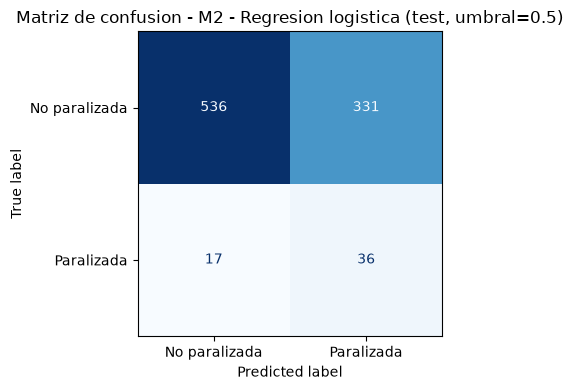

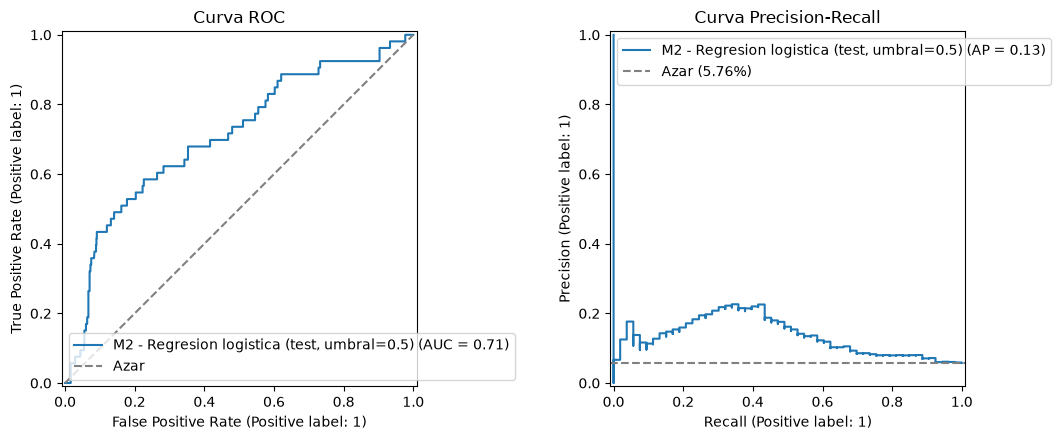

In [8]:
y_pred_m2 = classifier_m2.predict(X_test_m2)
y_proba_m2 = classifier_m2.predict_proba(X_test_m2)[:, 1]

metrics_m2 = reporte_evaluacion(
    y_test_m2, y_pred_m2, y_proba_m2,
    nombre_modelo="M2 - Regresion logistica (test, umbral=0.5)"
)


In [9]:
importancia_m2 = importancia_lineal_sklearn(classifier_m2, X_train_m2.columns, nombre_modelo="M2 - Regresion logistica")


**Variables y coeficientes - M2 - Regresion logistica**

| variable                                                           |   coeficiente |   abs_coeficiente |
|:-------------------------------------------------------------------|--------------:|------------------:|
| target_encoded__provincia_target_enc                               |        4.6585 |            4.6585 |
| categorical__naturaleza_obra_Instalación                           |       -2.0003 |            2.0003 |
| woe__codigo_entidad_woe                                            |        1.6916 |            1.6916 |
| target_encoded__tipo_obra_nivel_3_target_enc                       |        1.0963 |            1.0963 |
| categorical__naturaleza_obra_Rehabilitación                        |        1.0526 |            1.0526 |
| categorical__tipo_obra_nivel_1_Orden Público/Defensa Y Seguridad   |       -0.9089 |            0.9089 |
| target_encoded__departamento_target_enc                            |        0.8756 |            0.8756 |
| amount_log__monto_aprobado_soles_winsor_log                        |        0.7876 |            0.7876 |
| categorical__tipo_obra_nivel_1_Energía Y Minas                     |        0.7096 |            0.7096 |
| categorical__tipo_formato_1.0                                      |       -0.6077 |            0.6077 |
| categorical__tipo_obra_nivel_1_infrequent_sklearn                  |       -0.6026 |            0.6026 |
| categorical__naturaleza_obra_Reparación                            |       -0.5823 |            0.5823 |
| categorical__tipo_obra_nivel_1_Agricultura                         |       -0.5152 |            0.5152 |
| categorical__naturaleza_obra_Reconstrucción                        |        0.4854 |            0.4854 |
| categorical__tipo_obra_nivel_1_Otras Infraestructuras              |        0.4499 |            0.4499 |
| categorical__tipo_formato_5.0                                      |        0.448  |            0.448  |
| categorical__tipo_obra_nivel_1_Vivienda Construcción Y Saneamiento |        0.4474 |            0.4474 |
| categorical__naturaleza_obra_Remodelación                          |        0.4338 |            0.4338 |
| categorical__tipo_obra_nivel_1_Salud                               |        0.3461 |            0.3461 |
| categorical__naturaleza_obra_Renovación                            |        0.3218 |            0.3218 |
| categorical__naturaleza_obra_Ampliación                            |        0.3165 |            0.3165 |
| numeric_standard__n_obras_relacionadas_proyecto                    |       -0.2783 |            0.2783 |
| categorical__naturaleza_obra_infrequent_sklearn                    |       -0.2717 |            0.2717 |
| numeric_standard__inco_2024_entidad                                |        0.2698 |            0.2698 |
| numeric_standard__igeip_sector                                     |       -0.1976 |            0.1976 |
| categorical__tipo_obra_nivel_1_Transportes Y Comunicaciones        |       -0.1831 |            0.1831 |
| categorical__naturaleza_obra_Mejoramiento                          |        0.1594 |            0.1594 |
| categorical__naturaleza_obra_Construcción/Creación                 |       -0.1487 |            0.1487 |
| numeric_standard__igeip_sector_ejecucion                           |        0.11   |            0.11   |
| categorical__tipo_formato_2.0                                      |       -0.0738 |            0.0738 |
| target_encoded__tipo_obra_nivel_2_target_enc                       |       -0.0674 |            0.0674 |
| woe__sector_entidad_woe                                            |       -0.0356 |            0.0356 |
| categorical__tipo_obra_nivel_1_Educación/Cultura                   |        0.0234 |            0.0234 |

#### Metricas de entrenamiento (cross-validation 5-fold estratificado) - M2

In [10]:
scoring_cv = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "f2": make_scorer(fbeta_score, beta=2, zero_division=0),
}

skf_m2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results_m2 = cross_validate(
    classifier_m2, X_train_m2, y_train_m2,
    cv=skf_m2, scoring=scoring_cv, n_jobs=-1,
)

cv_summary_m2 = pd.DataFrame({m: cv_results_m2[f"test_{m}"] for m in scoring_cv})
cv_summary_m2.index = [f"fold_{i+1}" for i in range(len(cv_summary_m2))]
cv_summary_m2["gini"] = 2 * cv_summary_m2["roc_auc"] - 1
cv_summary_m2.loc["media"] = cv_summary_m2.mean()
cv_summary_m2.loc["std"] = cv_summary_m2.drop(index="media").std()

display(Markdown("**Cross-validation (5-fold estratificado) sobre train - M2**"))
display(Markdown(cv_summary_m2.round(4).to_markdown()))


**Cross-validation (5-fold estratificado) sobre train - M2**

|        |   roc_auc |   pr_auc |   precision |   recall |     f1 |     f2 |   gini |
|:-------|----------:|---------:|------------:|---------:|-------:|-------:|-------:|
| fold_1 |    0.8362 |   0.3668 |      0.2268 |   0.7586 | 0.3492 | 0.5164 | 0.6724 |
| fold_2 |    0.7946 |   0.3057 |      0.2368 |   0.6207 | 0.3429 | 0.4688 | 0.5893 |
| fold_3 |    0.8988 |   0.4258 |      0.2614 |   0.8214 | 0.3966 | 0.575  | 0.7976 |
| fold_4 |    0.8817 |   0.429  |      0.2529 |   0.7586 | 0.3793 | 0.5419 | 0.7635 |
| fold_5 |    0.8757 |   0.4889 |      0.2614 |   0.7931 | 0.3932 | 0.5637 | 0.7513 |
| media  |    0.8574 |   0.4032 |      0.2478 |   0.7505 | 0.3722 | 0.5332 | 0.7148 |
| std    |    0.0419 |   0.0695 |      0.0154 |   0.0772 | 0.0249 | 0.0424 | 0.0838 |

#### Analisis y seleccion del umbral de decision - M2

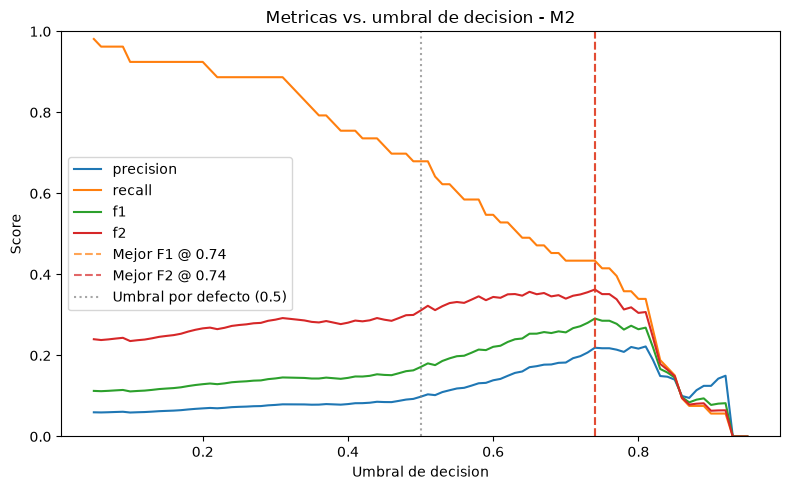

**Mejor umbral por F1 - M2**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.74 |       0.219 |    0.434 | 0.2911 | 0.3628 |

**Mejor umbral por F2 (prioriza recall) - M2**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.74 |       0.219 |    0.434 | 0.2911 | 0.3628 |

In [11]:
umbrales_m2 = analizar_umbrales(y_test_m2, y_proba_m2)
mejor_f1_m2, mejor_f2_m2 = graficar_umbrales(umbrales_m2, nombre_modelo="M2")

display(Markdown("**Mejor umbral por F1 - M2**"))
display(Markdown(mejor_f1_m2.to_frame().T.round(4).to_markdown(index=False)))

display(Markdown("**Mejor umbral por F2 (prioriza recall) - M2**"))
display(Markdown(mejor_f2_m2.to_frame().T.round(4).to_markdown(index=False)))


**Metricas globales - M2 - Regresion logistica (test, umbral=0.74)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.7074 |
| pr_auc    |  0.1335 |
| gini      |  0.4147 |
| precision |  0.219  |
| recall    |  0.434  |
| f1        |  0.2911 |
| f2        |  0.3628 |

**Reporte de clasificacion - M2 - Regresion logistica (test, umbral=0.74)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.963 |    0.905 |      0.933 |   867     |
| 1            |       0.219 |    0.434 |      0.291 |    53     |
| accuracy     |       0.878 |    0.878 |      0.878 |     0.878 |
| macro avg    |       0.591 |    0.67  |      0.612 |   920     |
| weighted avg |       0.92  |    0.878 |      0.896 |   920     |

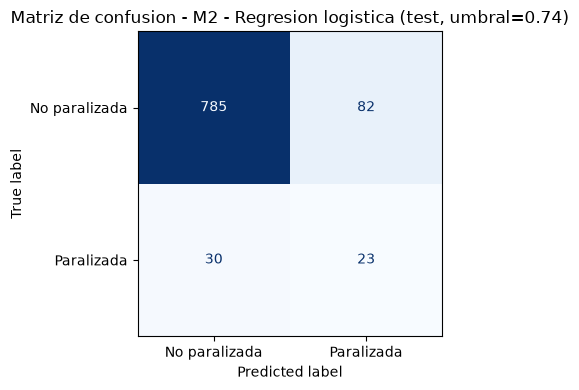

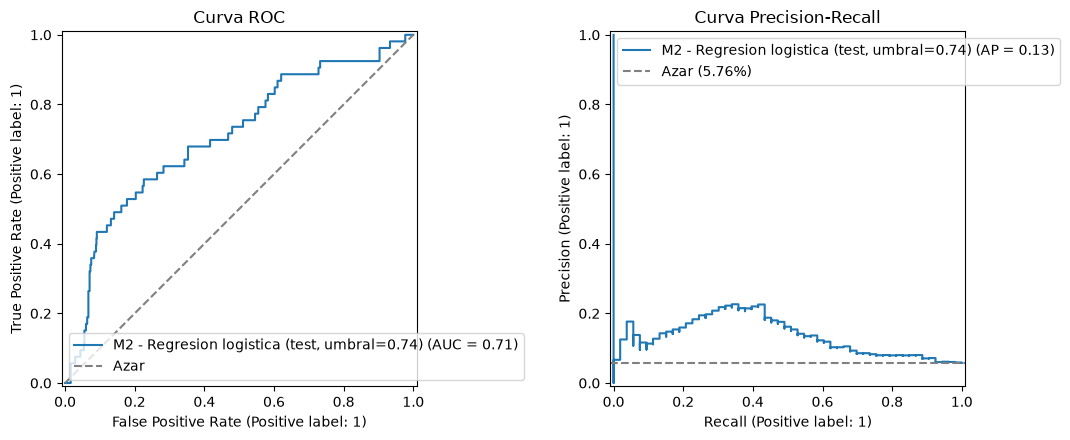

In [12]:
# Editar este valor para explorar manualmente otros umbrales de decision.
UMBRAL_DECISION_M2 = mejor_f2_m2["umbral"]

y_pred_m2_umbral = (y_proba_m2 >= UMBRAL_DECISION_M2).astype(int)

metrics_m2_umbral = reporte_evaluacion(
    y_test_m2, y_pred_m2_umbral, y_proba_m2,
    nombre_modelo=f"M2 - Regresion logistica (test, umbral={UMBRAL_DECISION_M2:.2f})"
)


## 5. M4: GLM binomial con enlace c-loglog

Se reutilizan las columnas de `X_train_m2`/`X_test_m2` (ya filtradas por el interruptor de la seccion 3), quitando una dummy de referencia por cada columna one-hot para evitar colinealidad perfecta con la constante del GLM.

In [18]:
columnas_glm = columnas_sin_colinealidad(X_train_m2.columns, COLUMNAS_ONEHOT_ORIGINALES)

X_design_train_m4 = sm.add_constant(X_train_m2[columnas_glm].to_numpy(), has_constant="add")
X_design_test_m4 = sm.add_constant(X_test_m2[columnas_glm].to_numpy(), has_constant="add")

print(f"Columnas GLM (sin colinealidad): {len(columnas_glm)} de {X_train_m2.shape[1]}")


Columnas GLM (sin colinealidad): 31 de 33


In [19]:
glm_m4 = sm.GLM(
    y_train_m2.to_numpy(),
    X_design_train_m4,
    family=sm.families.Binomial(link=sm.families.links.CLogLog()),
)
result_m4 = glm_m4.fit()

print(result_m4.summary().tables[0])


                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                 1707
Model:                            GLM   Df Residuals:                     1676
Model Family:                Binomial   Df Model:                           30
Link Function:                CLogLog   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -8565.6
Date:                Fri, 04 Sep 2026   Deviance:                       17131.
Time:                        17:56:48   Pearson chi2:                 8.38e+17
No. Iterations:                   100   Pseudo R-squ. (CS):         -1.280e+04
Covariance Type:            nonrobust                                         


c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\statsmodels\genmod\families\links.py:1035: RuntimeWarning: overflow encountered in exp
  return 1 - np.exp(-np.exp(z))
c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\statsmodels\genmod\families\links.py:1035: RuntimeWarning: overflow encountered in exp
  return 1 - np.exp(-np.exp(z))


**Metricas globales - M4 - GLM c-loglog (test, umbral=0.5)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.5336 |
| pr_auc    |  0.0634 |
| gini      |  0.0672 |
| precision |  0.0918 |
| recall    |  0.1698 |
| f1        |  0.1192 |
| f2        |  0.1452 |

**Reporte de clasificacion - M4 - GLM c-loglog (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.946 |    0.897 |      0.921 |   867     |
| 1            |       0.092 |    0.17  |      0.119 |    53     |
| accuracy     |       0.855 |    0.855 |      0.855 |     0.855 |
| macro avg    |       0.519 |    0.534 |      0.52  |   920     |
| weighted avg |       0.897 |    0.855 |      0.875 |   920     |

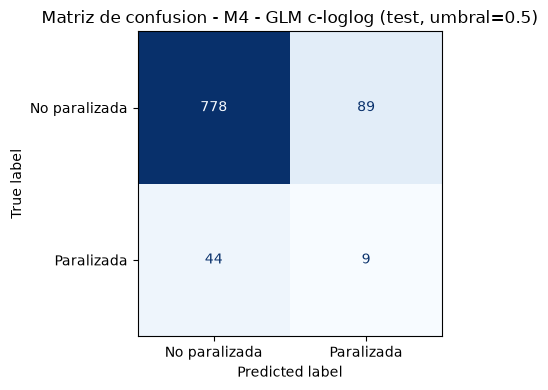

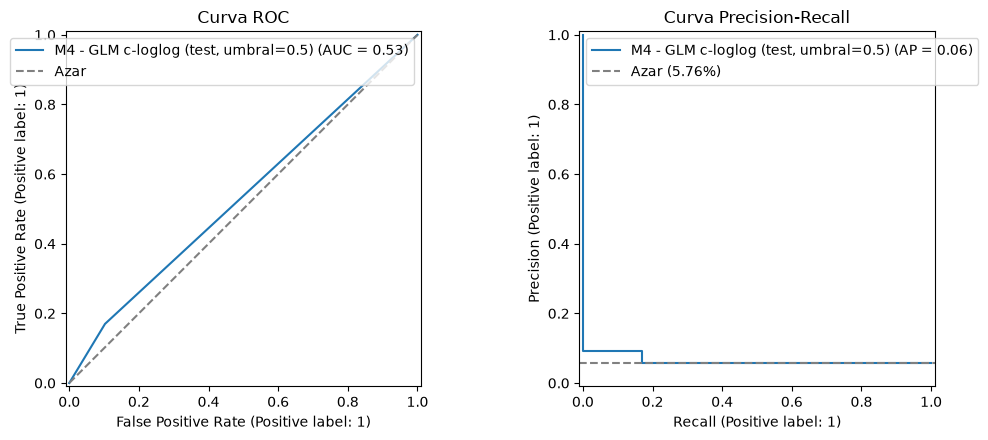

In [20]:
y_proba_m4 = np.asarray(result_m4.predict(X_design_test_m4))
y_pred_m4 = (y_proba_m4 >= 0.5).astype(int)

metrics_m4 = reporte_evaluacion(
    y_test_m2, y_pred_m4, y_proba_m4,
    nombre_modelo="M4 - GLM c-loglog (test, umbral=0.5)"
)


In [21]:
importancia_m4 = importancia_glm_statsmodels(result_m4, columnas_glm, nombre_modelo="M4 - GLM c-loglog")


**Variables, coeficientes y p-valores - M4 - GLM c-loglog**

| variable                                                           |   coeficiente |   p_valor |   abs_coeficiente |
|:-------------------------------------------------------------------|--------------:|----------:|------------------:|
| target_encoded__tipo_obra_nivel_2_target_enc                       |   1.37482e+15 |         0 |       1.37482e+15 |
| target_encoded__provincia_target_enc                               |   7.26343e+14 |         0 |       7.26343e+14 |
| target_encoded__tipo_obra_nivel_3_target_enc                       |   5.85633e+14 |         0 |       5.85633e+14 |
| categorical__tipo_obra_nivel_1_infrequent_sklearn                  |  -5.08454e+14 |         0 |       5.08454e+14 |
| categorical__tipo_obra_nivel_1_Orden Público/Defensa Y Seguridad   |  -4.9592e+14  |         0 |       4.9592e+14  |
| const                                                              |  -4.70884e+14 |         0 |       4.70884e+14 |
| categorical__tipo_obra_nivel_1_Vivienda Construcción Y Saneamiento |   3.52926e+14 |         0 |       3.52926e+14 |
| categorical__tipo_obra_nivel_1_Agricultura                         |  -3.21079e+14 |         0 |       3.21079e+14 |
| target_encoded__departamento_target_enc                            |  -2.1304e+14  |         0 |       2.1304e+14  |
| categorical__tipo_obra_nivel_1_Educación/Cultura                   |   2.08508e+14 |         0 |       2.08508e+14 |
| categorical__naturaleza_obra_Reconstrucción                        |   1.93312e+14 |         0 |       1.93312e+14 |
| categorical__naturaleza_obra_Rehabilitación                        |   1.65537e+14 |         0 |       1.65537e+14 |
| categorical__tipo_obra_nivel_1_Salud                               |   1.46126e+14 |         0 |       1.46126e+14 |
| categorical__naturaleza_obra_Renovación                            |   1.43216e+14 |         0 |       1.43216e+14 |
| woe__sector_entidad_woe                                            |   1.42358e+14 |         0 |       1.42358e+14 |
| woe__codigo_entidad_woe                                            |   1.10795e+14 |         0 |       1.10795e+14 |
| categorical__tipo_formato_5.0                                      |  -9.9015e+13  |         0 |       9.9015e+13  |
| categorical__naturaleza_obra_Remodelación                          |   7.76409e+13 |         0 |       7.76409e+13 |
| categorical__tipo_obra_nivel_1_Otras Infraestructuras              |   6.09462e+13 |         0 |       6.09462e+13 |
| categorical__tipo_obra_nivel_1_Transportes Y Comunicaciones        |   5.89768e+13 |         0 |       5.89768e+13 |
| categorical__naturaleza_obra_Construcción/Creación                 |   5.46893e+13 |         0 |       5.46893e+13 |
| categorical__naturaleza_obra_Instalación                           |  -5.3761e+13  |         0 |       5.3761e+13  |
| numeric_standard__igeip_sector_ejecucion                           |   5.18522e+13 |         0 |       5.18522e+13 |
| numeric_standard__igeip_sector                                     |  -3.78719e+13 |         0 |       3.78719e+13 |
| categorical__naturaleza_obra_Mejoramiento                          |   3.58246e+13 |         0 |       3.58246e+13 |
| categorical__tipo_formato_2.0                                      |   2.82741e+13 |         0 |       2.82741e+13 |
| categorical__tipo_obra_nivel_1_Energía Y Minas                     |   2.70856e+13 |         0 |       2.70856e+13 |
| categorical__naturaleza_obra_Reparación                            |   2.06896e+13 |         0 |       2.06896e+13 |
| categorical__naturaleza_obra_infrequent_sklearn                    |  -1.32664e+13 |         0 |       1.32664e+13 |
| numeric_standard__n_obras_relacionadas_proyecto                    |  -1.1206e+13  |         0 |       1.1206e+13  |
| numeric_standard__inco_2024_entidad                                |  -9.9084e+12  |         0 |       9.9084e+12  |
| amount_log__monto_aprobado_soles_winsor_log                        |  -1.95357e+11 |         0 |       1.95357e+11 |

#### Analisis y seleccion del umbral de decision - M4

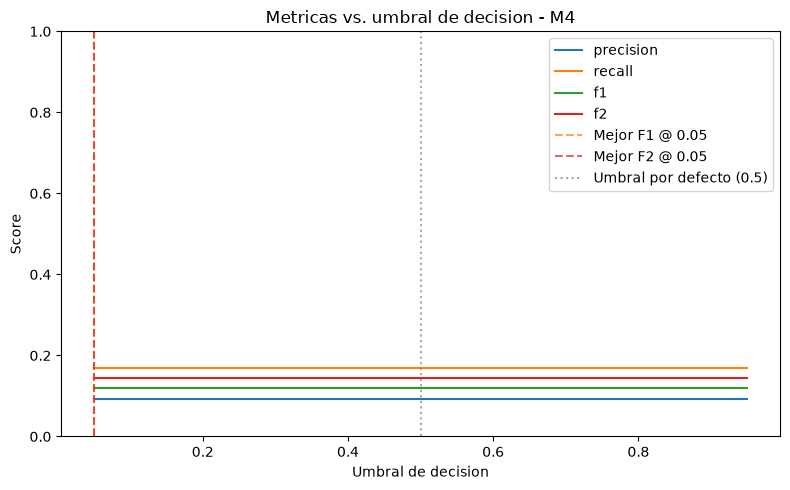

**Mejor umbral por F1 - M4**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.05 |      0.0918 |   0.1698 | 0.1192 | 0.1452 |

**Mejor umbral por F2 (prioriza recall) - M4**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.05 |      0.0918 |   0.1698 | 0.1192 | 0.1452 |

In [17]:
umbrales_m4 = analizar_umbrales(y_test_m2, y_proba_m4)
mejor_f1_m4, mejor_f2_m4 = graficar_umbrales(umbrales_m4, nombre_modelo="M4")

display(Markdown("**Mejor umbral por F1 - M4**"))
display(Markdown(mejor_f1_m4.to_frame().T.round(4).to_markdown(index=False)))

display(Markdown("**Mejor umbral por F2 (prioriza recall) - M4**"))
display(Markdown(mejor_f2_m4.to_frame().T.round(4).to_markdown(index=False)))


**Metricas globales - M4 - GLM c-loglog (test, umbral=0.05)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.5336 |
| pr_auc    |  0.0634 |
| gini      |  0.0672 |
| precision |  0.0918 |
| recall    |  0.1698 |
| f1        |  0.1192 |
| f2        |  0.1452 |

**Reporte de clasificacion - M4 - GLM c-loglog (test, umbral=0.05)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.946 |    0.897 |      0.921 |   867     |
| 1            |       0.092 |    0.17  |      0.119 |    53     |
| accuracy     |       0.855 |    0.855 |      0.855 |     0.855 |
| macro avg    |       0.519 |    0.534 |      0.52  |   920     |
| weighted avg |       0.897 |    0.855 |      0.875 |   920     |

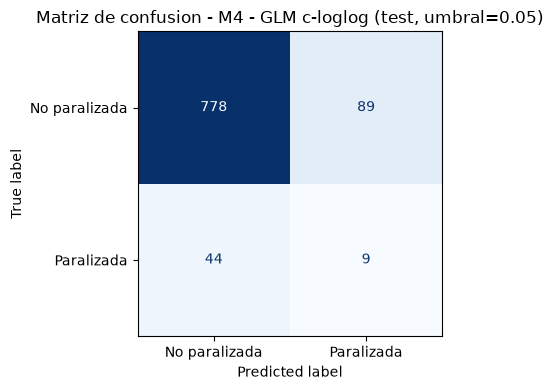

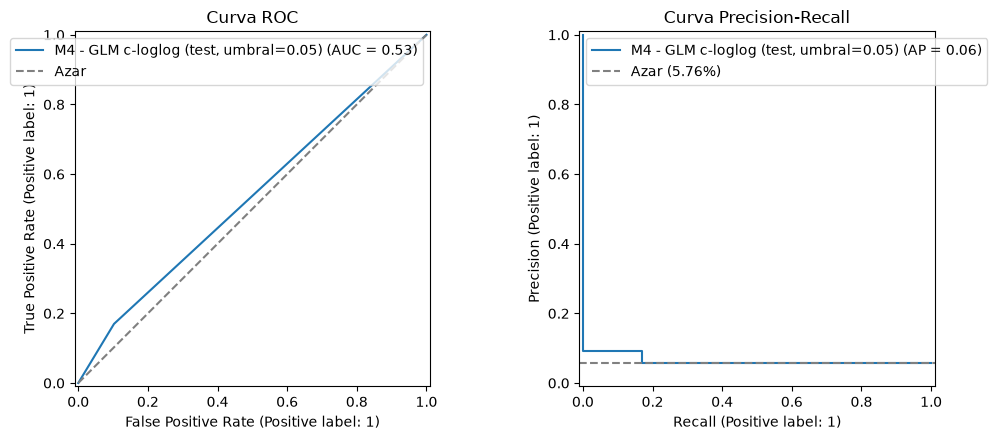

In [22]:
UMBRAL_DECISION_M4 = mejor_f2_m4["umbral"]

y_pred_m4_umbral = (y_proba_m4 >= UMBRAL_DECISION_M4).astype(int)

metrics_m4_umbral = reporte_evaluacion(
    y_test_m2, y_pred_m4_umbral, y_proba_m4,
    nombre_modelo=f"M4 - GLM c-loglog (test, umbral={UMBRAL_DECISION_M4:.2f})"
)


## 6. M6 y M7: GAM (logit / c-loglog)

Las columnas continuas (`amount_log`, `numeric_standard`, `target_encoded`, `woe`) entran como terminos suaves (splines); las columnas one-hot (`categorical`, ya sin la dummy de referencia) entran como parte lineal, igual que en `03_feature_engineering.ipynb`. Ambos modelos comparten preprocesamiento y base de splines; solo cambia el enlace del GLM.

In [23]:
columnas_suaves = [c for c in columnas_glm if not c.startswith("categorical__")]
columnas_lineales = [c for c in columnas_glm if c.startswith("categorical__")]

X_smooth_train = X_train_m2[columnas_suaves].to_numpy()
X_smooth_test = X_test_m2[columnas_suaves].to_numpy()
X_linear_train = X_train_m2[columnas_lineales].to_numpy()
X_linear_test = X_test_m2[columnas_lineales].to_numpy()

# Los splines de statsmodels no soportan extrapolar fuera de los knots
# (definidos con train); como el split es temporal, se recorta el test a
# los limites observados en train antes de predecir con el GAM.
limite_inf_gam = X_smooth_train.min(axis=0)
limite_sup_gam = X_smooth_train.max(axis=0)
X_smooth_test = np.clip(X_smooth_test, limite_inf_gam, limite_sup_gam)

bs_gam = BSplines(X_smooth_train, df=[5] * len(columnas_suaves), degree=[3] * len(columnas_suaves))

X_linear_train_const = sm.add_constant(X_linear_train, has_constant="add")
X_linear_test_const = sm.add_constant(X_linear_test, has_constant="add")

print(f"Columnas suaves: {len(columnas_suaves)} | Columnas lineales (dummies): {len(columnas_lineales)}")


Columnas suaves: 11 | Columnas lineales (dummies): 20


#### M6: GAM con enlace logit

In [24]:
gam_m6 = GLMGam(
    y_train_m2.to_numpy(),
    exog=X_linear_train_const,
    smoother=bs_gam,
    family=sm.families.Binomial(link=sm.families.links.Logit()),
    alpha=1.0,
)
result_m6 = gam_m6.fit()

print(result_m6.summary().tables[0])


                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                 1707
Model:                         GLMGam   Df Residuals:                  1673.04
Model Family:                Binomial   Df Model:                        32.96
Link Function:                  Logit   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -300.97
Date:                Fri, 04 Sep 2026   Deviance:                       601.94
Time:                        17:58:23   Pearson chi2:                 7.12e+03
No. Iterations:                    24   Pseudo R-squ. (CS):             0.2022
Covariance Type:            nonrobust                                         


**Metricas globales - M6 - GAM logit (test, umbral=0.5)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.708  |
| pr_auc    |  0.1866 |
| gini      |  0.416  |
| precision |  0.2273 |
| recall    |  0.0943 |
| f1        |  0.1333 |
| f2        |  0.1068 |

**Reporte de clasificacion - M6 - GAM logit (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.947 |    0.98  |      0.963 |   867     |
| 1            |       0.227 |    0.094 |      0.133 |    53     |
| accuracy     |       0.929 |    0.929 |      0.929 |     0.929 |
| macro avg    |       0.587 |    0.537 |      0.548 |   920     |
| weighted avg |       0.905 |    0.929 |      0.915 |   920     |

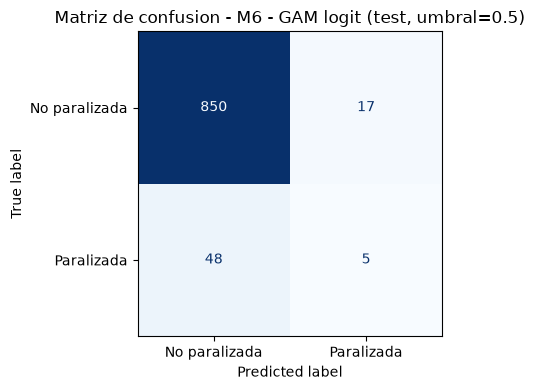

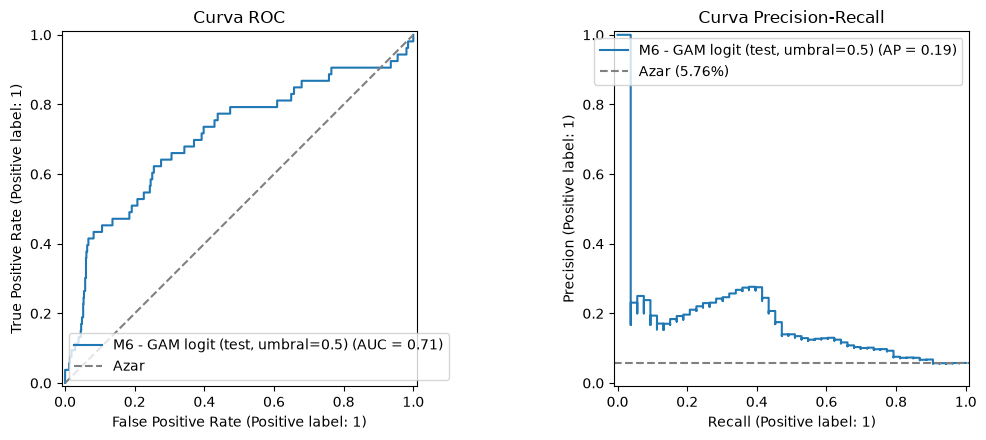

In [25]:
y_proba_m6 = np.asarray(result_m6.predict(exog=X_linear_test_const, exog_smooth=X_smooth_test))
y_pred_m6 = (y_proba_m6 >= 0.5).astype(int)

metrics_m6 = reporte_evaluacion(
    y_test_m2, y_pred_m6, y_proba_m6,
    nombre_modelo="M6 - GAM logit (test, umbral=0.5)"
)


In [26]:
importancia_m6 = importancia_gam_statsmodels(
    result_m6, columnas_lineales, columnas_suaves, bs_gam, nombre_modelo="M6 - GAM logit"
)


**Variables y peso - M6 - GAM logit** (`peso` = coeficiente para variables lineales/dummy; suma de |coeficientes de la base de splines| para variables suaves)

| variable                                                           | tipo           |     peso |   p_valor |   abs_peso |
|:-------------------------------------------------------------------|:---------------|---------:|----------:|-----------:|
| numeric_standard__n_obras_relacionadas_proyecto                    | suave (spline) |  58.8445 |  nan      |    58.8445 |
| const                                                              | lineal         | -32.6648 |    0.9996 |    32.6648 |
| categorical__tipo_obra_nivel_1_Orden Público/Defensa Y Seguridad   | lineal         | -19.5973 |    0.9996 |    19.5973 |
| categorical__tipo_obra_nivel_1_infrequent_sklearn                  | lineal         | -17.9555 |    0.9996 |    17.9555 |
| numeric_standard__igeip_sector                                     | suave (spline) |  15.4159 |  nan      |    15.4159 |
| woe__codigo_entidad_woe                                            | suave (spline) |  11.1935 |  nan      |    11.1935 |
| target_encoded__provincia_target_enc                               | suave (spline) |  11.0838 |  nan      |    11.0838 |
| amount_log__monto_aprobado_soles_winsor_log                        | suave (spline) |   8.2127 |  nan      |     8.2127 |
| numeric_standard__inco_2024_entidad                                | suave (spline) |   6.4028 |  nan      |     6.4028 |
| numeric_standard__igeip_sector_ejecucion                           | suave (spline) |   4.2025 |  nan      |     4.2025 |
| categorical__naturaleza_obra_Instalación                           | lineal         |  -3.595  |    0.0034 |     3.595  |
| woe__sector_entidad_woe                                            | suave (spline) |   3.0649 |  nan      |     3.0649 |
| target_encoded__tipo_obra_nivel_3_target_enc                       | suave (spline) |   2.4869 |  nan      |     2.4869 |
| target_encoded__departamento_target_enc                            | suave (spline) |   1.9595 |  nan      |     1.9595 |
| categorical__tipo_obra_nivel_1_Energía Y Minas                     | lineal         |   1.1796 |    1      |     1.1796 |
| categorical__tipo_obra_nivel_1_Otras Infraestructuras              | lineal         |   0.9448 |    1      |     0.9448 |
| target_encoded__tipo_obra_nivel_2_target_enc                       | suave (spline) |   0.8901 |  nan      |     0.8901 |
| categorical__tipo_obra_nivel_1_Vivienda Construcción Y Saneamiento | lineal         |   0.8859 |    1      |     0.8859 |
| categorical__tipo_formato_5.0                                      | lineal         |   0.8822 |    0.1364 |     0.8822 |
| categorical__tipo_obra_nivel_1_Salud                               | lineal         |   0.8346 |    1      |     0.8346 |
| categorical__tipo_obra_nivel_1_Educación/Cultura                   | lineal         |   0.7525 |    1      |     0.7525 |
| categorical__naturaleza_obra_infrequent_sklearn                    | lineal         |  -0.7183 |    0.5188 |     0.7183 |
| categorical__naturaleza_obra_Reparación                            | lineal         |  -0.6323 |    0.533  |     0.6323 |
| categorical__tipo_formato_2.0                                      | lineal         |   0.6298 |    0.1454 |     0.6298 |
| categorical__naturaleza_obra_Remodelación                          | lineal         |   0.5987 |    0.4234 |     0.5987 |
| categorical__naturaleza_obra_Rehabilitación                        | lineal         |   0.5783 |    0.4124 |     0.5783 |
| categorical__naturaleza_obra_Construcción/Creación                 | lineal         |  -0.5114 |    0.4059 |     0.5114 |
| categorical__tipo_obra_nivel_1_Transportes Y Comunicaciones        | lineal         |   0.4953 |    1      |     0.4953 |
| categorical__naturaleza_obra_Renovación                            | lineal         |   0.2967 |    0.6829 |     0.2967 |
| categorical__naturaleza_obra_Mejoramiento                          | lineal         |  -0.2853 |    0.5929 |     0.2853 |
| categorical__tipo_obra_nivel_1_Agricultura                         | lineal         |  -0.2045 |    1      |     0.2045 |
| categorical__naturaleza_obra_Reconstrucción                        | lineal         |   0.1169 |    0.8755 |     0.1169 |

#### Analisis y seleccion del umbral de decision - M6

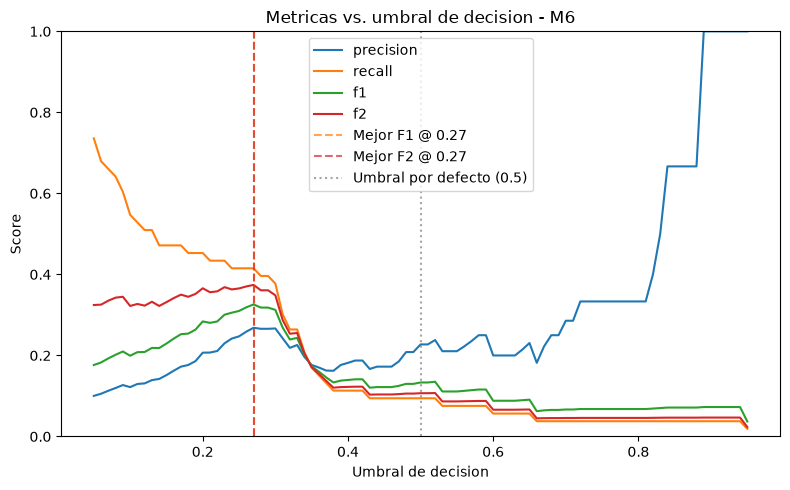

**Mejor umbral por F1 - M6**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.27 |      0.2683 |   0.4151 | 0.3259 | 0.3741 |

**Mejor umbral por F2 (prioriza recall) - M6**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.27 |      0.2683 |   0.4151 | 0.3259 | 0.3741 |

In [27]:
umbrales_m6 = analizar_umbrales(y_test_m2, y_proba_m6)
mejor_f1_m6, mejor_f2_m6 = graficar_umbrales(umbrales_m6, nombre_modelo="M6")

display(Markdown("**Mejor umbral por F1 - M6**"))
display(Markdown(mejor_f1_m6.to_frame().T.round(4).to_markdown(index=False)))

display(Markdown("**Mejor umbral por F2 (prioriza recall) - M6**"))
display(Markdown(mejor_f2_m6.to_frame().T.round(4).to_markdown(index=False)))


**Metricas globales - M6 - GAM logit (test, umbral=0.27)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.708  |
| pr_auc    |  0.1866 |
| gini      |  0.416  |
| precision |  0.2683 |
| recall    |  0.4151 |
| f1        |  0.3259 |
| f2        |  0.3741 |

**Reporte de clasificacion - M6 - GAM logit (test, umbral=0.27)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.963 |    0.931 |      0.947 |   867     |
| 1            |       0.268 |    0.415 |      0.326 |    53     |
| accuracy     |       0.901 |    0.901 |      0.901 |     0.901 |
| macro avg    |       0.616 |    0.673 |      0.636 |   920     |
| weighted avg |       0.923 |    0.901 |      0.911 |   920     |

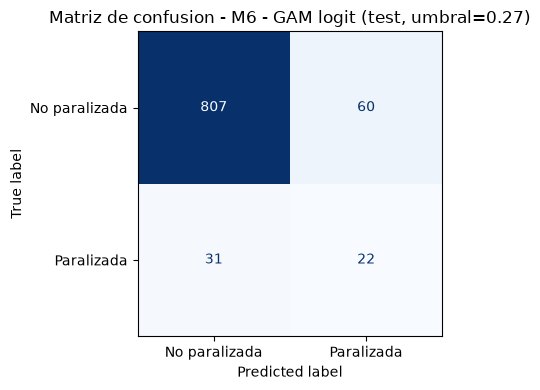

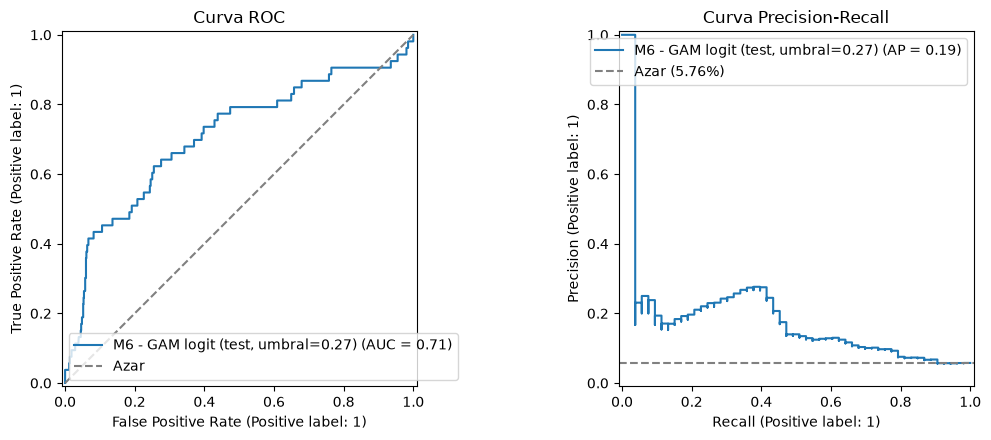

In [28]:
UMBRAL_DECISION_M6 = mejor_f2_m6["umbral"]

y_pred_m6_umbral = (y_proba_m6 >= UMBRAL_DECISION_M6).astype(int)

metrics_m6_umbral = reporte_evaluacion(
    y_test_m2, y_pred_m6_umbral, y_proba_m6,
    nombre_modelo=f"M6 - GAM logit (test, umbral={UMBRAL_DECISION_M6:.2f})"
)


#### M7: GAM con enlace c-loglog

In [29]:
gam_m7 = GLMGam(
    y_train_m2.to_numpy(),
    exog=X_linear_train_const,
    smoother=bs_gam,
    family=sm.families.Binomial(link=sm.families.links.CLogLog()),
    alpha=1.0,
)
result_m7 = gam_m7.fit()

print(result_m7.summary().tables[0])


                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                 1707
Model:                         GLMGam   Df Residuals:                  1671.45
Model Family:                Binomial   Df Model:                        34.55
Link Function:                CLogLog   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -298.84
Date:                Fri, 04 Sep 2026   Deviance:                       597.69
Time:                        17:59:47   Pearson chi2:                 5.42e+03
No. Iterations:                    28   Pseudo R-squ. (CS):             0.2042
Covariance Type:            nonrobust                                         


**Metricas globales - M7 - GAM c-loglog (test, umbral=0.5)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.7109 |
| pr_auc    |  0.1955 |
| gini      |  0.4218 |
| precision |  0.2083 |
| recall    |  0.0943 |
| f1        |  0.1299 |
| f2        |  0.1059 |

**Reporte de clasificacion - M7 - GAM c-loglog (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.946 |    0.978 |      0.962 |   867     |
| 1            |       0.208 |    0.094 |      0.13  |    53     |
| accuracy     |       0.927 |    0.927 |      0.927 |     0.927 |
| macro avg    |       0.577 |    0.536 |      0.546 |   920     |
| weighted avg |       0.904 |    0.927 |      0.914 |   920     |

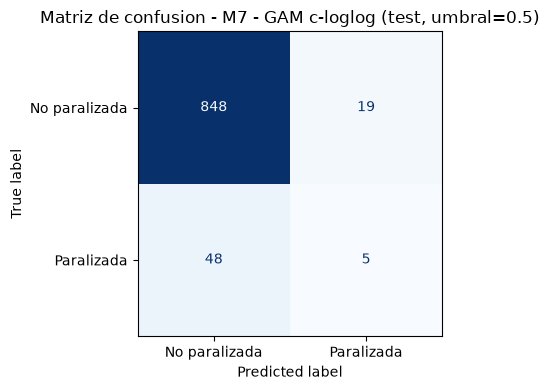

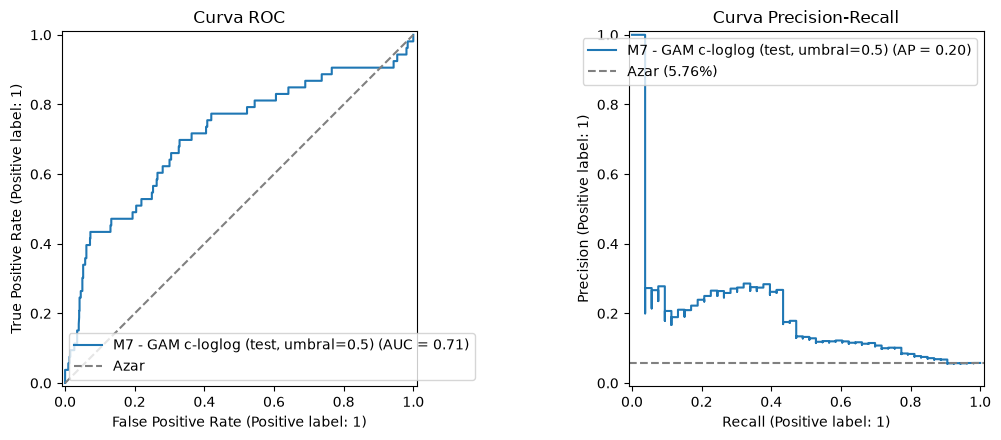

In [30]:
y_proba_m7 = np.asarray(result_m7.predict(exog=X_linear_test_const, exog_smooth=X_smooth_test))
y_pred_m7 = (y_proba_m7 >= 0.5).astype(int)

metrics_m7 = reporte_evaluacion(
    y_test_m2, y_pred_m7, y_proba_m7,
    nombre_modelo="M7 - GAM c-loglog (test, umbral=0.5)"
)


In [31]:
importancia_m7 = importancia_gam_statsmodels(
    result_m7, columnas_lineales, columnas_suaves, bs_gam, nombre_modelo="M7 - GAM c-loglog"
)


**Variables y peso - M7 - GAM c-loglog** (`peso` = coeficiente para variables lineales/dummy; suma de |coeficientes de la base de splines| para variables suaves)

| variable                                                           | tipo           |     peso |   p_valor |   abs_peso |
|:-------------------------------------------------------------------|:---------------|---------:|----------:|-----------:|
| numeric_standard__n_obras_relacionadas_proyecto                    | suave (spline) |  58.5478 |  nan      |    58.5478 |
| const                                                              | lineal         | -32.1127 |    0.9996 |    32.1127 |
| categorical__tipo_obra_nivel_1_Orden Público/Defensa Y Seguridad   | lineal         | -19.2582 |    0.9996 |    19.2582 |
| numeric_standard__igeip_sector                                     | suave (spline) |  18.8347 |  nan      |    18.8347 |
| categorical__tipo_obra_nivel_1_infrequent_sklearn                  | lineal         | -18.0038 |    0.9996 |    18.0038 |
| woe__codigo_entidad_woe                                            | suave (spline) |  10.5001 |  nan      |    10.5001 |
| target_encoded__provincia_target_enc                               | suave (spline) |   9.1054 |  nan      |     9.1054 |
| amount_log__monto_aprobado_soles_winsor_log                        | suave (spline) |   8.1387 |  nan      |     8.1387 |
| numeric_standard__igeip_sector_ejecucion                           | suave (spline) |   6.7252 |  nan      |     6.7252 |
| numeric_standard__inco_2024_entidad                                | suave (spline) |   5.6559 |  nan      |     5.6559 |
| woe__sector_entidad_woe                                            | suave (spline) |   5.037  |  nan      |     5.037  |
| categorical__naturaleza_obra_Instalación                           | lineal         |  -3.2922 |    0.0044 |     3.2922 |
| target_encoded__tipo_obra_nivel_3_target_enc                       | suave (spline) |   1.9404 |  nan      |     1.9404 |
| target_encoded__departamento_target_enc                            | suave (spline) |   1.4467 |  nan      |     1.4467 |
| categorical__tipo_obra_nivel_1_Energía Y Minas                     | lineal         |   1.1906 |    1      |     1.1906 |
| categorical__tipo_obra_nivel_1_Vivienda Construcción Y Saneamiento | lineal         |   0.8151 |    1      |     0.8151 |
| categorical__tipo_obra_nivel_1_Salud                               | lineal         |   0.8145 |    1      |     0.8145 |
| categorical__tipo_obra_nivel_1_Educación/Cultura                   | lineal         |   0.8131 |    1      |     0.8131 |
| categorical__naturaleza_obra_Rehabilitación                        | lineal         |   0.687  |    0.2585 |     0.687  |
| categorical__tipo_obra_nivel_1_Otras Infraestructuras              | lineal         |   0.6767 |    1      |     0.6767 |
| categorical__tipo_formato_5.0                                      | lineal         |   0.6703 |    0.2061 |     0.6703 |
| categorical__naturaleza_obra_Remodelación                          | lineal         |   0.6455 |    0.3328 |     0.6455 |
| categorical__tipo_obra_nivel_1_Transportes Y Comunicaciones        | lineal         |   0.5831 |    1      |     0.5831 |
| categorical__naturaleza_obra_infrequent_sklearn                    | lineal         |  -0.5619 |    0.5598 |     0.5619 |
| categorical__tipo_formato_2.0                                      | lineal         |   0.5584 |    0.1609 |     0.5584 |
| categorical__naturaleza_obra_Construcción/Creación                 | lineal         |  -0.441  |    0.4157 |     0.441  |
| target_encoded__tipo_obra_nivel_2_target_enc                       | suave (spline) |   0.4324 |  nan      |     0.4324 |
| categorical__naturaleza_obra_Renovación                            | lineal         |   0.3866 |    0.5491 |     0.3866 |
| categorical__naturaleza_obra_Reconstrucción                        | lineal         |   0.3368 |    0.6025 |     0.3368 |
| categorical__naturaleza_obra_Reparación                            | lineal         |  -0.3257 |    0.7198 |     0.3257 |
| categorical__tipo_obra_nivel_1_Agricultura                         | lineal         |   0.2562 |    1      |     0.2562 |
| categorical__naturaleza_obra_Mejoramiento                          | lineal         |  -0.1459 |    0.7398 |     0.1459 |

#### Analisis y seleccion del umbral de decision - M7

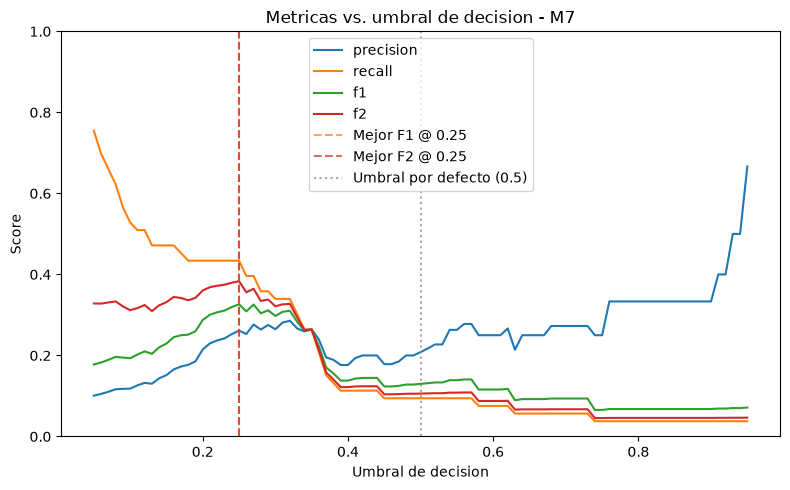

**Mejor umbral por F1 - M7**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.25 |      0.2614 |    0.434 | 0.3262 | 0.3833 |

**Mejor umbral por F2 (prioriza recall) - M7**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.25 |      0.2614 |    0.434 | 0.3262 | 0.3833 |

In [32]:
umbrales_m7 = analizar_umbrales(y_test_m2, y_proba_m7)
mejor_f1_m7, mejor_f2_m7 = graficar_umbrales(umbrales_m7, nombre_modelo="M7")

display(Markdown("**Mejor umbral por F1 - M7**"))
display(Markdown(mejor_f1_m7.to_frame().T.round(4).to_markdown(index=False)))

display(Markdown("**Mejor umbral por F2 (prioriza recall) - M7**"))
display(Markdown(mejor_f2_m7.to_frame().T.round(4).to_markdown(index=False)))


**Metricas globales - M7 - GAM c-loglog (test, umbral=0.25)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.7109 |
| pr_auc    |  0.1955 |
| gini      |  0.4218 |
| precision |  0.2614 |
| recall    |  0.434  |
| f1        |  0.3262 |
| f2        |  0.3833 |

**Reporte de clasificacion - M7 - GAM c-loglog (test, umbral=0.25)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.964 |    0.925 |      0.944 |   867     |
| 1            |       0.261 |    0.434 |      0.326 |    53     |
| accuracy     |       0.897 |    0.897 |      0.897 |     0.897 |
| macro avg    |       0.613 |    0.679 |      0.635 |   920     |
| weighted avg |       0.923 |    0.897 |      0.908 |   920     |

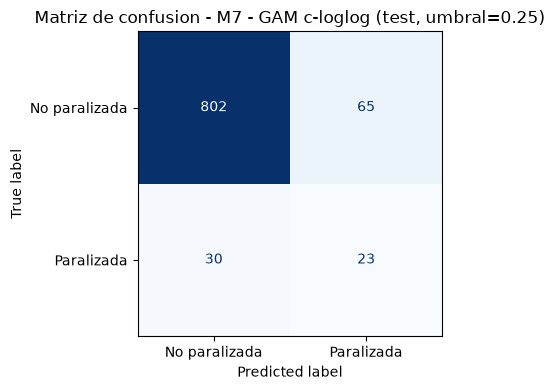

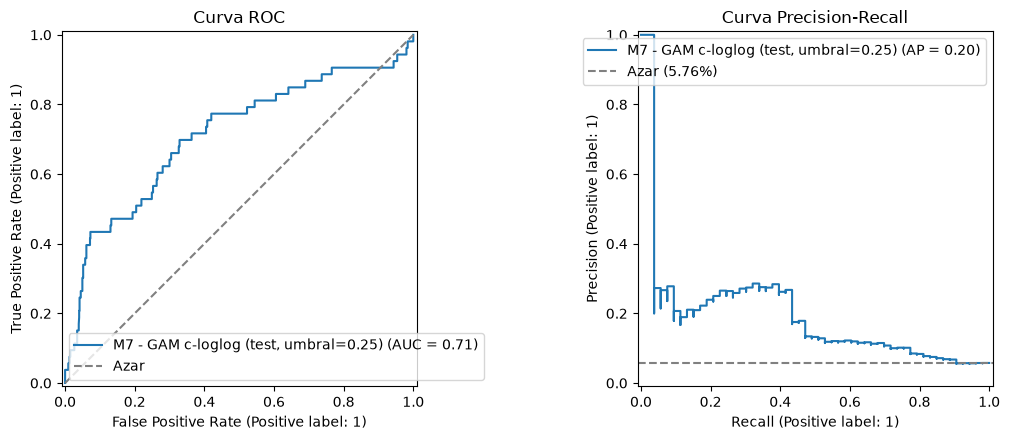

In [33]:
UMBRAL_DECISION_M7 = mejor_f2_m7["umbral"]

y_pred_m7_umbral = (y_proba_m7 >= UMBRAL_DECISION_M7).astype(int)

metrics_m7_umbral = reporte_evaluacion(
    y_test_m2, y_pred_m7_umbral, y_proba_m7,
    nombre_modelo=f"M7 - GAM c-loglog (test, umbral={UMBRAL_DECISION_M7:.2f})"
)


## 7. Benchmark de Machine Learning: Random Forest

Referencia no lineal / no parametrica frente a los GLM/GAM anteriores, sobre las mismas columnas seleccionadas en la seccion 3 (sin necesidad de quitar dummies: los arboles no tienen problema de colinealidad). Para el desbalance de clases se usa `class_weight="balanced_subsample"`.

In [34]:
classifier_rf = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=5,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1,
)
classifier_rf.fit(X_train_m2, y_train_m2)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced_subsample'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consid

**Metricas globales - RF - Random Forest benchmark (test, umbral=0.5)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.6477 |
| pr_auc    |  0.1533 |
| gini      |  0.2955 |
| precision |  0.1261 |
| recall    |  0.283  |
| f1        |  0.1744 |
| f2        |  0.2266 |

**Reporte de clasificacion - RF - Random Forest benchmark (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.953 |    0.88  |      0.915 |   867     |
| 1            |       0.126 |    0.283 |      0.174 |    53     |
| accuracy     |       0.846 |    0.846 |      0.846 |     0.846 |
| macro avg    |       0.539 |    0.582 |      0.545 |   920     |
| weighted avg |       0.905 |    0.846 |      0.872 |   920     |

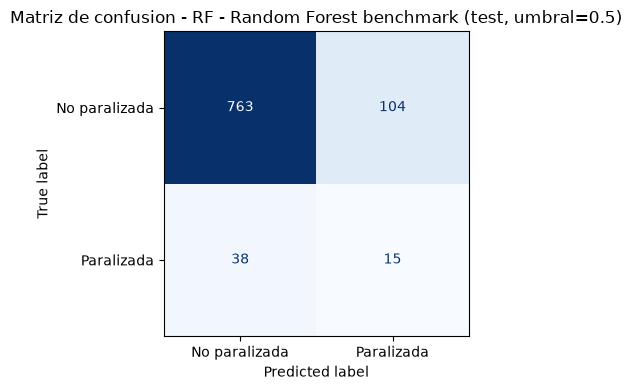

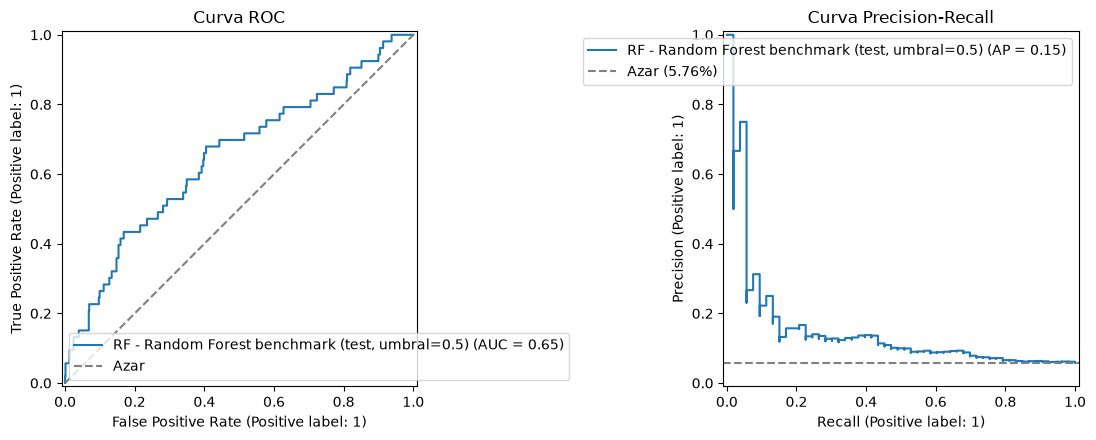

In [35]:
y_pred_rf = classifier_rf.predict(X_test_m2)
y_proba_rf = classifier_rf.predict_proba(X_test_m2)[:, 1]

metrics_rf = reporte_evaluacion(
    y_test_m2, y_pred_rf, y_proba_rf,
    nombre_modelo="RF - Random Forest benchmark (test, umbral=0.5)"
)


In [36]:
importancia_rf = importancia_arbol(classifier_rf, X_train_m2.columns, nombre_modelo="RF - Random Forest")


**Variables e importancia (impureza) - RF - Random Forest**

| variable                                                           |   importancia |
|:-------------------------------------------------------------------|--------------:|
| woe__codigo_entidad_woe                                            |        0.1909 |
| target_encoded__provincia_target_enc                               |        0.1775 |
| amount_log__monto_aprobado_soles_winsor_log                        |        0.1694 |
| target_encoded__tipo_obra_nivel_3_target_enc                       |        0.0819 |
| numeric_standard__inco_2024_entidad                                |        0.0474 |
| target_encoded__tipo_obra_nivel_2_target_enc                       |        0.0451 |
| target_encoded__departamento_target_enc                            |        0.043  |
| woe__sector_entidad_woe                                            |        0.0418 |
| categorical__naturaleza_obra_Instalación                           |        0.0384 |
| categorical__naturaleza_obra_Rehabilitación                        |        0.0225 |
| categorical__tipo_formato_2.0                                      |        0.0188 |
| numeric_standard__igeip_sector                                     |        0.0184 |
| numeric_standard__igeip_sector_ejecucion                           |        0.0178 |
| categorical__tipo_formato_5.0                                      |        0.0165 |
| categorical__tipo_formato_1.0                                      |        0.0082 |
| categorical__naturaleza_obra_Construcción/Creación                 |        0.008  |
| categorical__tipo_obra_nivel_1_Transportes Y Comunicaciones        |        0.0077 |
| categorical__naturaleza_obra_Mejoramiento                          |        0.0054 |
| categorical__tipo_obra_nivel_1_Educación/Cultura                   |        0.0053 |
| categorical__naturaleza_obra_Reconstrucción                        |        0.0052 |
| categorical__tipo_obra_nivel_1_Energía Y Minas                     |        0.0052 |
| categorical__tipo_obra_nivel_1_Agricultura                         |        0.0047 |
| categorical__tipo_obra_nivel_1_Otras Infraestructuras              |        0.0042 |
| categorical__naturaleza_obra_Ampliación                            |        0.0038 |
| categorical__tipo_obra_nivel_1_Salud                               |        0.003  |
| categorical__tipo_obra_nivel_1_Vivienda Construcción Y Saneamiento |        0.0029 |
| categorical__naturaleza_obra_Renovación                            |        0.0029 |
| categorical__naturaleza_obra_Remodelación                          |        0.0025 |
| categorical__naturaleza_obra_Reparación                            |        0.0008 |
| categorical__naturaleza_obra_infrequent_sklearn                    |        0.0006 |
| categorical__tipo_obra_nivel_1_Orden Público/Defensa Y Seguridad   |        0.0003 |
| categorical__tipo_obra_nivel_1_infrequent_sklearn                  |        0      |
| numeric_standard__n_obras_relacionadas_proyecto                    |        0      |

#### Metricas de entrenamiento (cross-validation 5-fold estratificado) - Random Forest

In [37]:
skf_rf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results_rf = cross_validate(
    classifier_rf, X_train_m2, y_train_m2,
    cv=skf_rf, scoring=scoring_cv, n_jobs=-1,
)

cv_summary_rf = pd.DataFrame({m: cv_results_rf[f"test_{m}"] for m in scoring_cv})
cv_summary_rf.index = [f"fold_{i+1}" for i in range(len(cv_summary_rf))]
cv_summary_rf["gini"] = 2 * cv_summary_rf["roc_auc"] - 1
cv_summary_rf.loc["media"] = cv_summary_rf.mean()
cv_summary_rf.loc["std"] = cv_summary_rf.drop(index="media").std()

display(Markdown("**Cross-validation (5-fold estratificado) sobre train - Random Forest**"))
display(Markdown(cv_summary_rf.round(4).to_markdown()))


**Cross-validation (5-fold estratificado) sobre train - Random Forest**

|        |   roc_auc |   pr_auc |   precision |   recall |     f1 |     f2 |   gini |
|:-------|----------:|---------:|------------:|---------:|-------:|-------:|-------:|
| fold_1 |    0.911  |   0.6217 |      0.4222 |   0.6552 | 0.5135 | 0.5901 | 0.822  |
| fold_2 |    0.8559 |   0.5024 |      0.3269 |   0.5862 | 0.4198 | 0.506  | 0.7118 |
| fold_3 |    0.8959 |   0.5195 |      0.3721 |   0.5714 | 0.4507 | 0.5161 | 0.7919 |
| fold_4 |    0.9319 |   0.6261 |      0.4074 |   0.7586 | 0.5301 | 0.6471 | 0.8638 |
| fold_5 |    0.8974 |   0.6242 |      0.4524 |   0.6552 | 0.5352 | 0.6013 | 0.7949 |
| media  |    0.8984 |   0.5788 |      0.3962 |   0.6453 | 0.4899 | 0.5721 | 0.7969 |
| std    |    0.0278 |   0.0622 |      0.0483 |   0.0741 | 0.0517 | 0.0598 | 0.0556 |

#### Analisis y seleccion del umbral de decision - Random Forest

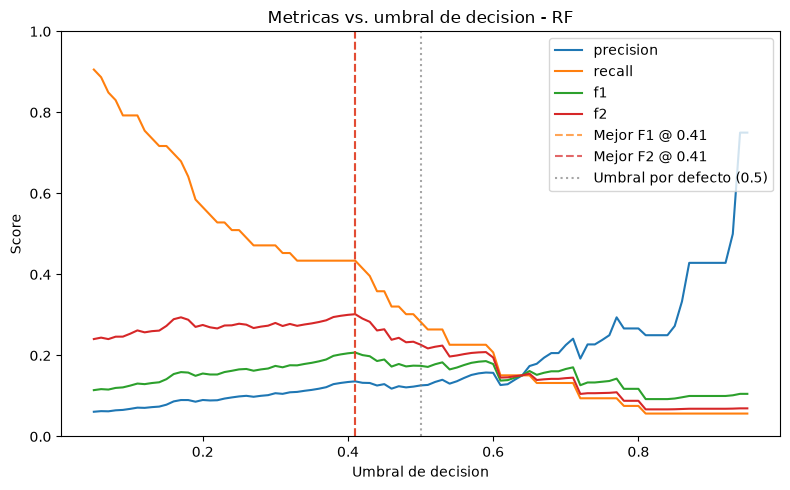

**Mejor umbral por F1 - RF**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.41 |      0.1361 |    0.434 | 0.2072 | 0.3018 |

**Mejor umbral por F2 (prioriza recall) - RF**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.41 |      0.1361 |    0.434 | 0.2072 | 0.3018 |

In [38]:
umbrales_rf = analizar_umbrales(y_test_m2, y_proba_rf)
mejor_f1_rf, mejor_f2_rf = graficar_umbrales(umbrales_rf, nombre_modelo="RF")

display(Markdown("**Mejor umbral por F1 - RF**"))
display(Markdown(mejor_f1_rf.to_frame().T.round(4).to_markdown(index=False)))

display(Markdown("**Mejor umbral por F2 (prioriza recall) - RF**"))
display(Markdown(mejor_f2_rf.to_frame().T.round(4).to_markdown(index=False)))


**Metricas globales - RF - Random Forest benchmark (test, umbral=0.41)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.6477 |
| pr_auc    |  0.1533 |
| gini      |  0.2955 |
| precision |  0.1361 |
| recall    |  0.434  |
| f1        |  0.2072 |
| f2        |  0.3018 |

**Reporte de clasificacion - RF - Random Forest benchmark (test, umbral=0.41)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.96  |    0.832 |      0.891 |   867     |
| 1            |       0.136 |    0.434 |      0.207 |    53     |
| accuracy     |       0.809 |    0.809 |      0.809 |     0.809 |
| macro avg    |       0.548 |    0.633 |      0.549 |   920     |
| weighted avg |       0.913 |    0.809 |      0.852 |   920     |

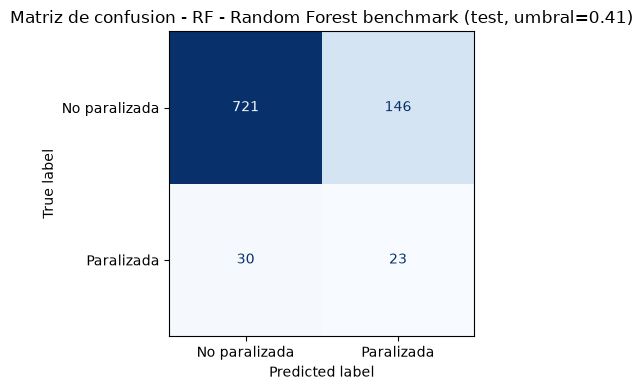

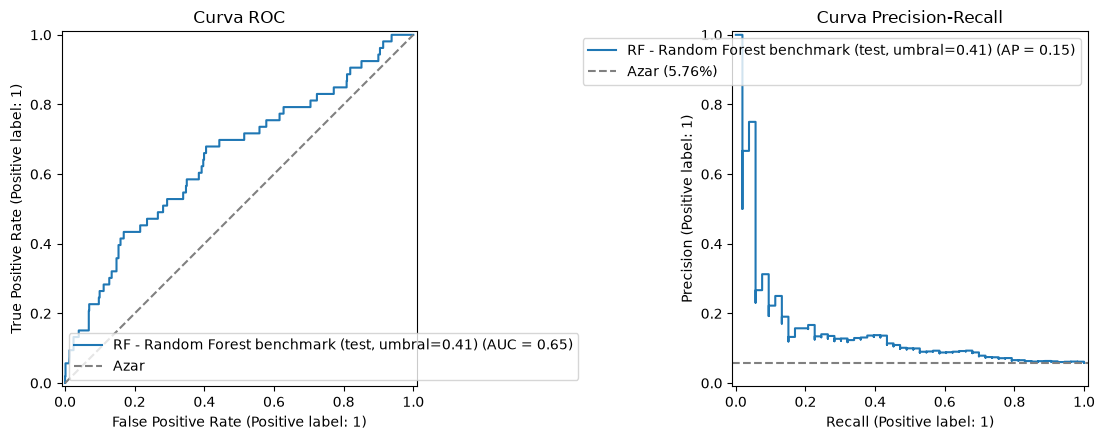

In [39]:
UMBRAL_DECISION_RF = mejor_f2_rf["umbral"]

y_pred_rf_umbral = (y_proba_rf >= UMBRAL_DECISION_RF).astype(int)

metrics_rf_umbral = reporte_evaluacion(
    y_test_m2, y_pred_rf_umbral, y_proba_rf,
    nombre_modelo=f"RF - Random Forest benchmark (test, umbral={UMBRAL_DECISION_RF:.2f})"
)


## 8. Comparativa general (M2, M4, M6, M7, RF) - test, umbral=0.5

In [40]:
comparativa_modelos = pd.DataFrame(
    [metrics_m2, metrics_m4, metrics_m6, metrics_m7, metrics_rf],
    index=[
        "M2 - Regresion logistica",
        "M4 - GLM c-loglog",
        "M6 - GAM logit",
        "M7 - GAM c-loglog",
        "RF - Random Forest",
    ],
)
display(Markdown(comparativa_modelos.round(4).to_markdown()))


|                          |   roc_auc |   pr_auc |   gini |   precision |   recall |     f1 |     f2 |
|:-------------------------|----------:|---------:|-------:|------------:|---------:|-------:|-------:|
| M2 - Regresion logistica |    0.7074 |   0.1335 | 0.4147 |      0.0981 |   0.6792 | 0.1714 | 0.3109 |
| M4 - GLM c-loglog        |    0.5336 |   0.0634 | 0.0672 |      0.0918 |   0.1698 | 0.1192 | 0.1452 |
| M6 - GAM logit           |    0.708  |   0.1866 | 0.416  |      0.2273 |   0.0943 | 0.1333 | 0.1068 |
| M7 - GAM c-loglog        |    0.7109 |   0.1955 | 0.4218 |      0.2083 |   0.0943 | 0.1299 | 0.1059 |
| RF - Random Forest       |    0.6477 |   0.1533 | 0.2955 |      0.1261 |   0.283  | 0.1744 | 0.2266 |

## 9. Diagnostico: por que M2 tiene mejor recall/F2 que M4, M6 y M7 a umbral=0.5, y modelos mejorados para el desbalance

**No es la codificacion (WOE/target encoding).** Los cinco modelos reciben exactamente las mismas columnas de `X_train_m2`/`X_test_m2` (controladas por el interruptor de la seccion 3), asi que si el encoding perjudicara al modelo lo haria por igual en todos. La prueba esta en el propio ROC AUC / PR AUC de la tabla de la seccion 8: M6 y M7 tienen **ROC AUC y PR AUC iguales o mejores que M2** (0.6946-0.6966 vs 0.6929), es decir, ordenan los casos de riesgo igual o mejor que M2. El problema no es la capacidad discriminativa del modelo, sino el **umbral de decision fijo en 0.5**.

**Si es la ponderacion de clases.** `classifier_m2 = LogisticRegression(class_weight="balanced")` no entrena sobre la tasa real (~7% positivos): reescala internamente la funcion de perdida para que cada clase pese lo mismo en el ajuste, lo cual **desplaza el intercepto** del modelo hacia arriba. El efecto practico es que M2 predice `P(Y=1|X) >= 0.5` con mucha mas frecuencia, lo que sube el recall (llega a mas casos positivos reales) a costa de la precision (tambien dispara los falsos positivos).

`M4`, `M6` y `M7` en cambio se ajustaron por **maxima verosimilitud sin ponderar** (`sm.GLM`/`GLMGam` estandar): sus probabilidades predichas SI estan bien calibradas a la tasa real de paralizacion (~7%), por lo que casi ningun caso supera el umbral de 0.5 -> recall muy bajo, pero no porque el modelo sea peor, sino porque el umbral de 0.5 es demasiado alto para una clase tan minoritaria. De hecho, la seccion de "Analisis y seleccion del umbral" de cada modelo ya muestra que, moviendo el umbral al optimo por F2 (`UMBRAL_DECISION_M4/M6/M7`), recall y F2 de M4/M6/M7 se acercan mucho o superan a M2.

**Que se agrega aqui:** en vez de solo mover el umbral, se entrena una **variante ponderada** de M4, M5 (nuevo, ver abajo), M6 y M7 usando pesos de clase balanceados (`pesos_balanceados_train`, seccion 3, misma formula que `class_weight="balanced"` de sklearn) directamente en el ajuste por maxima verosimilitud -- el equivalente, para un GLM/GAM, de la ponderacion "cost-sensitive" que ya usa M2. Esto es distinto de la regularizacion L1/L2 (que penaliza el tamano de los coeficientes para reducir varianza, no el desbalance de clases): aqui se pondera el **costo del error** por clase durante el ajuste, no el tamano de los coeficientes.

> Nota tecnica: `statsmodels` permite ponderar por clase de dos formas distintas segun el modelo -- `sm.GLM(..., freq_weights=pesos)` para GLM "planos" (M4, M5), y `GLMGam(...).fit(weights=pesos)` para GAM (M6, M7). El parametro `freq_weights` pasado al **constructor** de `GLMGam` se guarda pero el metodo `.fit(method="pirls")` de esta version de `statsmodels` no lo usa; hay que pasar `weights=` directamente a `.fit()` para que el ajuste PIRLS lo aplique.

### M5: GLM binomial con enlace probit

Ninguno de los modelos anteriores usa el enlace probit: M2 usa logit (via scikit-learn), M4 usa c-loglog. El probit (`Phi^-1(p)`, inversa de la CDF normal estandar) es simetrico como el logit pero con colas mas delgadas; en la practica suele dar resultados muy similares al logit. Se reutiliza la misma matriz de diseno que M4 (`X_design_train_m4`/`X_design_test_m4`, columnas `columnas_glm`).

In [41]:
glm_m5 = sm.GLM(
    y_train_m2.to_numpy(),
    X_design_train_m4,
    family=sm.families.Binomial(link=sm.families.links.Probit()),
)
result_m5 = glm_m5.fit()

print(result_m5.summary().tables[0])


                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                 1707
Model:                            GLM   Df Residuals:                     1676
Model Family:                Binomial   Df Model:                           30
Link Function:                 Probit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -9164.3
Date:                Fri, 04 Sep 2026   Deviance:                       18329.
Time:                        18:03:30   Pearson chi2:                 8.96e+17
No. Iterations:                    63   Pseudo R-squ. (CS):         -2.581e+04
Covariance Type:            nonrobust                                         


c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


**Metricas globales - M5 - GLM probit (test, umbral=0.5)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.5047 |
| pr_auc    |  0.0582 |
| gini      |  0.0093 |
| precision |  0.0682 |
| recall    |  0.0566 |
| f1        |  0.0619 |
| f2        |  0.0586 |

**Reporte de clasificacion - M5 - GLM probit (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.943 |    0.953 |      0.948 |   867     |
| 1            |       0.068 |    0.057 |      0.062 |    53     |
| accuracy     |       0.901 |    0.901 |      0.901 |     0.901 |
| macro avg    |       0.506 |    0.505 |      0.505 |   920     |
| weighted avg |       0.893 |    0.901 |      0.897 |   920     |

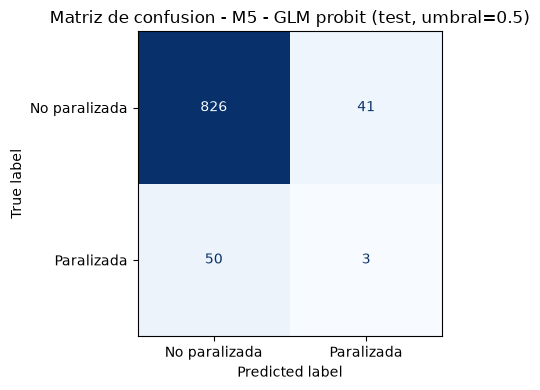

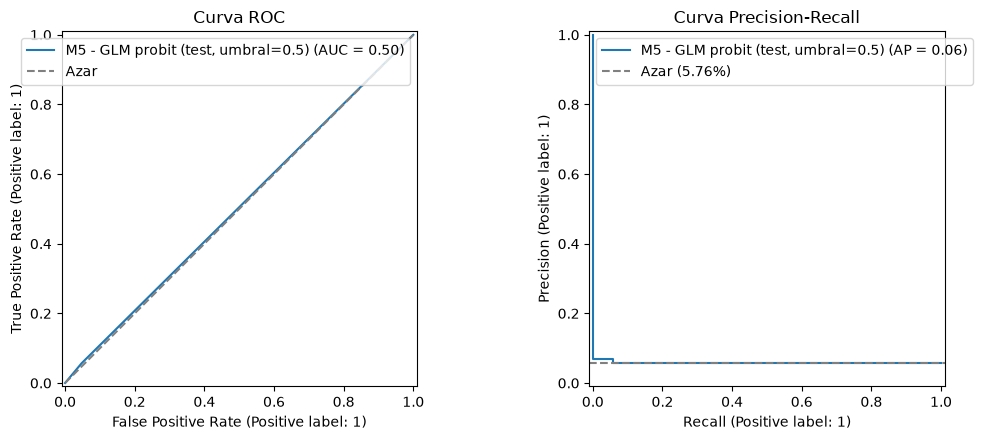

In [42]:
y_proba_m5 = np.asarray(result_m5.predict(X_design_test_m4))
y_pred_m5 = (y_proba_m5 >= 0.5).astype(int)

metrics_m5 = reporte_evaluacion(
    y_test_m2, y_pred_m5, y_proba_m5,
    nombre_modelo="M5 - GLM probit (test, umbral=0.5)"
)


In [43]:
importancia_m5 = importancia_glm_statsmodels(result_m5, columnas_glm, nombre_modelo="M5 - GLM probit")


**Variables, coeficientes y p-valores - M5 - GLM probit**

| variable                                                           |   coeficiente |   p_valor |   abs_coeficiente |
|:-------------------------------------------------------------------|--------------:|----------:|------------------:|
| target_encoded__provincia_target_enc                               |   1.27621e+15 |         0 |       1.27621e+15 |
| target_encoded__tipo_obra_nivel_3_target_enc                       |   5.20466e+14 |         0 |       5.20466e+14 |
| target_encoded__departamento_target_enc                            |  -4.32712e+14 |         0 |       4.32712e+14 |
| categorical__tipo_obra_nivel_1_infrequent_sklearn                  |  -3.09258e+14 |         0 |       3.09258e+14 |
| const                                                              |  -2.80391e+14 |         0 |       2.80391e+14 |
| categorical__naturaleza_obra_Instalación                           |  -2.09462e+14 |         0 |       2.09462e+14 |
| categorical__tipo_obra_nivel_1_Transportes Y Comunicaciones        |  -2.06952e+14 |         0 |       2.06952e+14 |
| target_encoded__tipo_obra_nivel_2_target_enc                       |   1.52949e+14 |         0 |       1.52949e+14 |
| categorical__tipo_formato_5.0                                      |   1.00465e+14 |         0 |       1.00465e+14 |
| categorical__tipo_obra_nivel_1_Educación/Cultura                   |   8.6767e+13  |         0 |       8.6767e+13  |
| categorical__naturaleza_obra_infrequent_sklearn                    |  -8.3236e+13  |         0 |       8.3236e+13  |
| categorical__naturaleza_obra_Reconstrucción                        |  -7.71538e+13 |         0 |       7.71538e+13 |
| categorical__tipo_obra_nivel_1_Otras Infraestructuras              |   6.9513e+13  |         0 |       6.9513e+13  |
| categorical__tipo_obra_nivel_1_Vivienda Construcción Y Saneamiento |   5.99464e+13 |         0 |       5.99464e+13 |
| categorical__tipo_obra_nivel_1_Energía Y Minas                     |   5.4933e+13  |         0 |       5.4933e+13  |
| categorical__tipo_formato_2.0                                      |   4.73744e+13 |         0 |       4.73744e+13 |
| woe__codigo_entidad_woe                                            |   4.72417e+13 |         0 |       4.72417e+13 |
| categorical__naturaleza_obra_Construcción/Creación                 |  -4.25053e+13 |         0 |       4.25053e+13 |
| numeric_standard__igeip_sector                                     |   3.6883e+13  |         0 |       3.6883e+13  |
| categorical__naturaleza_obra_Reparación                            |  -2.71992e+13 |         0 |       2.71992e+13 |
| numeric_standard__n_obras_relacionadas_proyecto                    |  -2.41566e+13 |         0 |       2.41566e+13 |
| numeric_standard__igeip_sector_ejecucion                           |  -2.35681e+13 |         0 |       2.35681e+13 |
| categorical__naturaleza_obra_Mejoramiento                          |  -1.98519e+13 |         0 |       1.98519e+13 |
| categorical__naturaleza_obra_Rehabilitación                        |  -1.70915e+13 |         0 |       1.70915e+13 |
| amount_log__monto_aprobado_soles_winsor_log                        |   1.58648e+13 |         0 |       1.58648e+13 |
| categorical__tipo_obra_nivel_1_Orden Público/Defensa Y Seguridad   |  -1.31638e+13 |         0 |       1.31638e+13 |
| categorical__tipo_obra_nivel_1_Salud                               |  -1.26445e+13 |         0 |       1.26445e+13 |
| categorical__tipo_obra_nivel_1_Agricultura                         |  -9.53207e+12 |         0 |       9.53207e+12 |
| numeric_standard__inco_2024_entidad                                |   9.08178e+12 |         0 |       9.08178e+12 |
| woe__sector_entidad_woe                                            |  -8.55678e+12 |         0 |       8.55678e+12 |
| categorical__naturaleza_obra_Remodelación                          |   2.61112e+12 |         0 |       2.61112e+12 |
| categorical__naturaleza_obra_Renovación                            |  -1.09441e+12 |         0 |       1.09441e+12 |

#### Analisis y seleccion del umbral de decision - M5

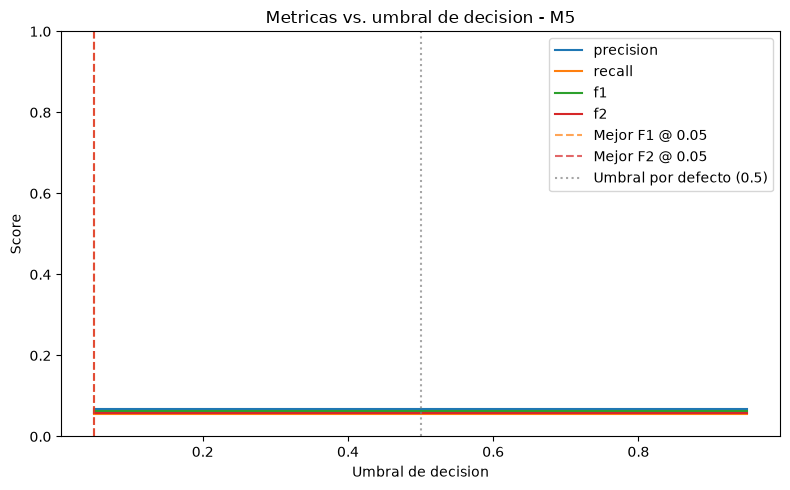

**Mejor umbral por F1 - M5**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.05 |      0.0682 |   0.0566 | 0.0619 | 0.0586 |

**Mejor umbral por F2 (prioriza recall) - M5**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.05 |      0.0682 |   0.0566 | 0.0619 | 0.0586 |

In [44]:
umbrales_m5 = analizar_umbrales(y_test_m2, y_proba_m5)
mejor_f1_m5, mejor_f2_m5 = graficar_umbrales(umbrales_m5, nombre_modelo="M5")

display(Markdown("**Mejor umbral por F1 - M5**"))
display(Markdown(mejor_f1_m5.to_frame().T.round(4).to_markdown(index=False)))

display(Markdown("**Mejor umbral por F2 (prioriza recall) - M5**"))
display(Markdown(mejor_f2_m5.to_frame().T.round(4).to_markdown(index=False)))


**Metricas globales - M5 - GLM probit (test, umbral=0.05)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.5047 |
| pr_auc    |  0.0582 |
| gini      |  0.0093 |
| precision |  0.0682 |
| recall    |  0.0566 |
| f1        |  0.0619 |
| f2        |  0.0586 |

**Reporte de clasificacion - M5 - GLM probit (test, umbral=0.05)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.943 |    0.953 |      0.948 |   867     |
| 1            |       0.068 |    0.057 |      0.062 |    53     |
| accuracy     |       0.901 |    0.901 |      0.901 |     0.901 |
| macro avg    |       0.506 |    0.505 |      0.505 |   920     |
| weighted avg |       0.893 |    0.901 |      0.897 |   920     |

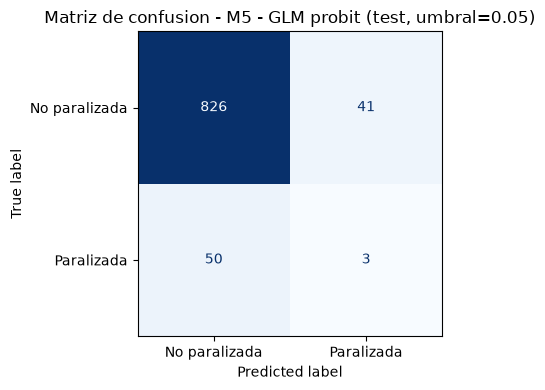

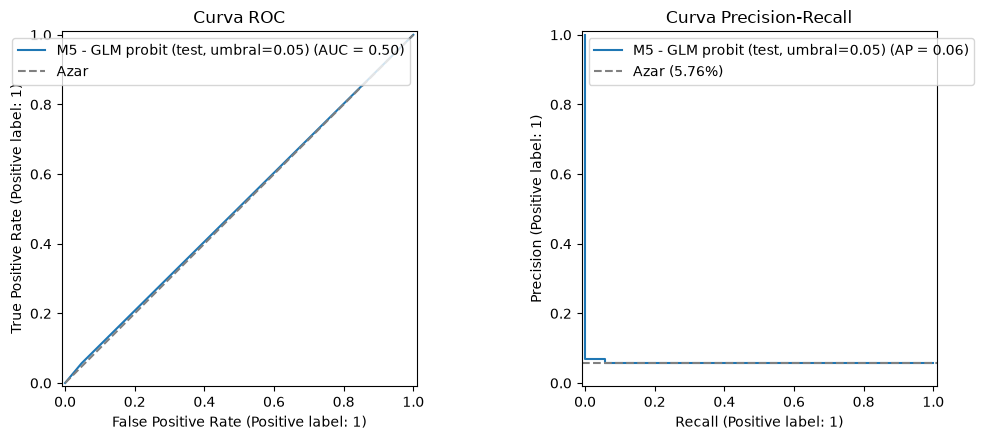

In [45]:
UMBRAL_DECISION_M5 = mejor_f2_m5["umbral"]

y_pred_m5_umbral = (y_proba_m5 >= UMBRAL_DECISION_M5).astype(int)

metrics_m5_umbral = reporte_evaluacion(
    y_test_m2, y_pred_m5_umbral, y_proba_m5,
    nombre_modelo=f"M5 - GLM probit (test, umbral={UMBRAL_DECISION_M5:.2f})"
)


### Variantes ponderadas (pesos de clase balanceados) de M4, M5, M6 y M7

Mismo modelo y mismas columnas que las versiones originales; unico cambio: se pasan `pesos_balanceados_train` al ajuste por maxima verosimilitud. Se evaluan directamente al umbral por defecto (0.5) para comparar de forma justa contra M2 (que tambien usa `class_weight` y se evalua a 0.5).

#### M4 ponderado: GLM c-loglog con pesos de clase balanceados

c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\statsmodels\genmod\families\links.py:1035: RuntimeWarning: overflow encountered in exp
  return 1 - np.exp(-np.exp(z))
c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


**Metricas globales - M4 ponderado - GLM c-loglog (test, umbral=0.5)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.5261 |
| pr_auc    |  0.0616 |
| gini      |  0.0522 |
| precision |  0.0811 |
| recall    |  0.1698 |
| f1        |  0.1098 |
| f2        |  0.1393 |

**Reporte de clasificacion - M4 ponderado - GLM c-loglog (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.946 |    0.882 |      0.913 |   867     |
| 1            |       0.081 |    0.17  |      0.11  |    53     |
| accuracy     |       0.841 |    0.841 |      0.841 |     0.841 |
| macro avg    |       0.513 |    0.526 |      0.511 |   920     |
| weighted avg |       0.896 |    0.841 |      0.867 |   920     |

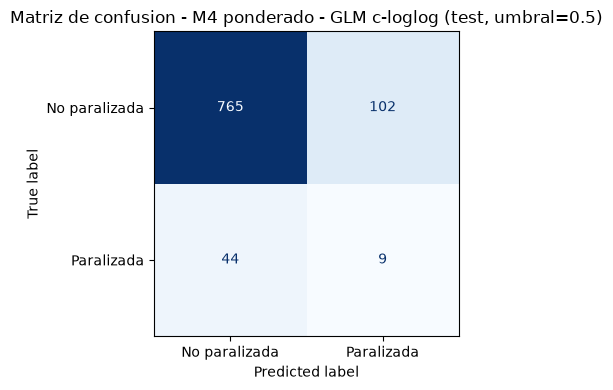

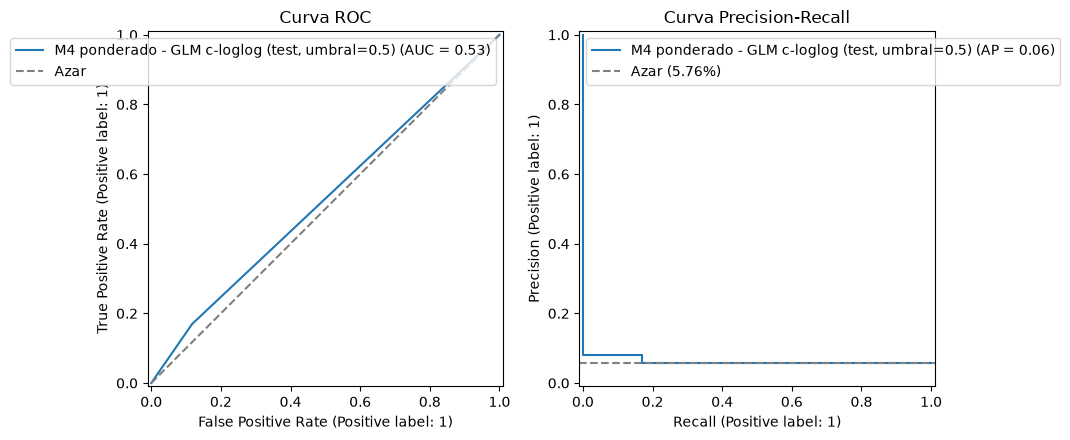

In [46]:
glm_m4_w = sm.GLM(
    y_train_m2.to_numpy(),
    X_design_train_m4,
    family=sm.families.Binomial(link=sm.families.links.CLogLog()),
    freq_weights=pesos_balanceados_train,
)
result_m4_w = glm_m4_w.fit()

y_proba_m4_w = np.asarray(result_m4_w.predict(X_design_test_m4))
y_pred_m4_w = (y_proba_m4_w >= 0.5).astype(int)

metrics_m4_w = reporte_evaluacion(
    y_test_m2, y_pred_m4_w, y_proba_m4_w,
    nombre_modelo="M4 ponderado - GLM c-loglog (test, umbral=0.5)"
)


In [47]:
importancia_m4_w = importancia_glm_statsmodels(result_m4_w, columnas_glm, nombre_modelo="M4 ponderado - GLM c-loglog")


**Variables, coeficientes y p-valores - M4 ponderado - GLM c-loglog**

| variable                                                           |   coeficiente |   p_valor |   abs_coeficiente |
|:-------------------------------------------------------------------|--------------:|----------:|------------------:|
| target_encoded__provincia_target_enc                               |   1.51628e+15 |         0 |       1.51628e+15 |
| categorical__naturaleza_obra_Reparación                            |   8.00486e+14 |         0 |       8.00486e+14 |
| categorical__tipo_obra_nivel_1_Orden Público/Defensa Y Seguridad   |  -6.91565e+14 |         0 |       6.91565e+14 |
| categorical__tipo_obra_nivel_1_infrequent_sklearn                  |  -5.68967e+14 |         0 |       5.68967e+14 |
| categorical__naturaleza_obra_infrequent_sklearn                    |   5.68079e+14 |         0 |       5.68079e+14 |
| const                                                              |  -5.49649e+14 |         0 |       5.49649e+14 |
| target_encoded__departamento_target_enc                            |  -4.42294e+14 |         0 |       4.42294e+14 |
| categorical__tipo_formato_5.0                                      |   3.52455e+14 |         0 |       3.52455e+14 |
| categorical__naturaleza_obra_Remodelación                          |   3.52405e+14 |         0 |       3.52405e+14 |
| target_encoded__tipo_obra_nivel_3_target_enc                       |   3.30938e+14 |         0 |       3.30938e+14 |
| categorical__tipo_obra_nivel_1_Salud                               |   2.99682e+14 |         0 |       2.99682e+14 |
| target_encoded__tipo_obra_nivel_2_target_enc                       |   2.45927e+14 |         0 |       2.45927e+14 |
| categorical__naturaleza_obra_Instalación                           |  -2.43507e+14 |         0 |       2.43507e+14 |
| categorical__tipo_obra_nivel_1_Energía Y Minas                     |   2.00866e+14 |         0 |       2.00866e+14 |
| categorical__tipo_obra_nivel_1_Transportes Y Comunicaciones        |   1.9737e+14  |         0 |       1.9737e+14  |
| categorical__naturaleza_obra_Reconstrucción                        |  -1.8921e+14  |         0 |       1.8921e+14  |
| categorical__naturaleza_obra_Renovación                            |  -1.79048e+14 |         0 |       1.79048e+14 |
| categorical__naturaleza_obra_Rehabilitación                        |  -1.72123e+14 |         0 |       1.72123e+14 |
| categorical__tipo_formato_2.0                                      |  -1.50853e+14 |         0 |       1.50853e+14 |
| categorical__tipo_obra_nivel_1_Educación/Cultura                   |   1.24982e+14 |         0 |       1.24982e+14 |
| woe__codigo_entidad_woe                                            |   1.22854e+14 |         0 |       1.22854e+14 |
| numeric_standard__igeip_sector                                     |  -1.09936e+14 |         0 |       1.09936e+14 |
| categorical__tipo_obra_nivel_1_Otras Infraestructuras              |  -1.09028e+14 |         0 |       1.09028e+14 |
| numeric_standard__igeip_sector_ejecucion                           |   1.0012e+14  |         0 |       1.0012e+14  |
| categorical__tipo_obra_nivel_1_Agricultura                         |  -7.79327e+13 |         0 |       7.79327e+13 |
| amount_log__monto_aprobado_soles_winsor_log                        |   7.5941e+13  |         0 |       7.5941e+13  |
| categorical__tipo_obra_nivel_1_Vivienda Construcción Y Saneamiento |   7.49445e+13 |         0 |       7.49445e+13 |
| woe__sector_entidad_woe                                            |   5.01192e+13 |         0 |       5.01192e+13 |
| numeric_standard__n_obras_relacionadas_proyecto                    |  -4.15977e+13 |         0 |       4.15977e+13 |
| categorical__naturaleza_obra_Construcción/Creación                 |  -3.60822e+13 |         0 |       3.60822e+13 |
| numeric_standard__inco_2024_entidad                                |  -1.4852e+13  |         0 |       1.4852e+13  |
| categorical__naturaleza_obra_Mejoramiento                          |   7.40181e+12 |         0 |       7.40181e+12 |

#### M5 ponderado: GLM probit con pesos de clase balanceados

c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


**Metricas globales - M5 ponderado - GLM probit (test, umbral=0.5)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.5238 |
| pr_auc    |  0.0608 |
| gini      |  0.0476 |
| precision |  0.0719 |
| recall    |  0.2264 |
| f1        |  0.1091 |
| f2        |  0.1583 |

**Reporte de clasificacion - M5 ponderado - GLM probit (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.946 |    0.821 |      0.879 |   867     |
| 1            |       0.072 |    0.226 |      0.109 |    53     |
| accuracy     |       0.787 |    0.787 |      0.787 |     0.787 |
| macro avg    |       0.509 |    0.524 |      0.494 |   920     |
| weighted avg |       0.895 |    0.787 |      0.835 |   920     |

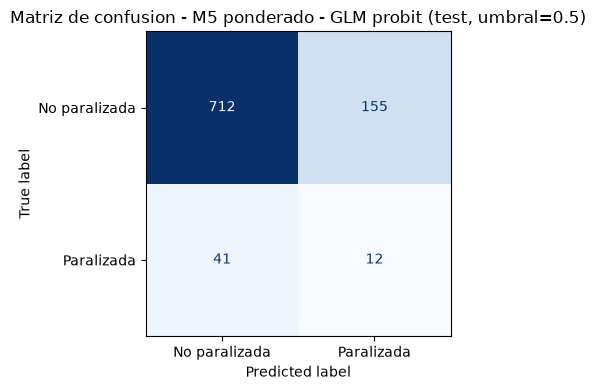

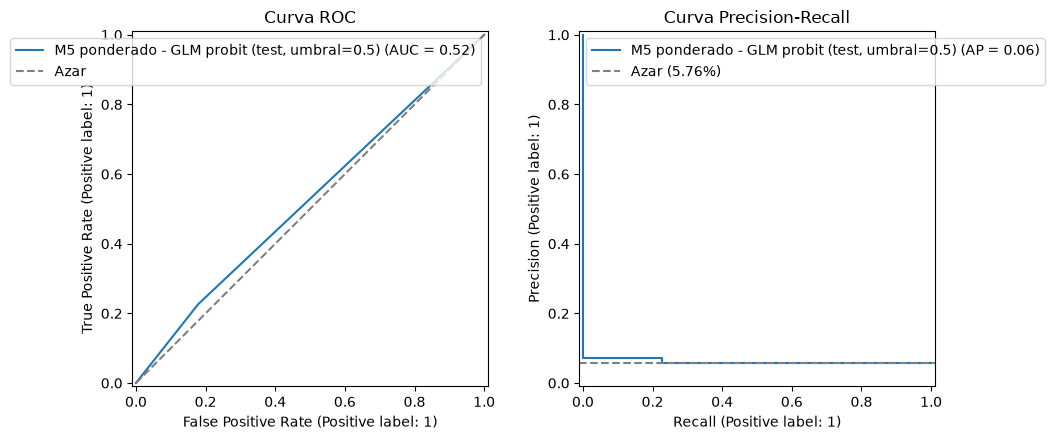

In [48]:
glm_m5_w = sm.GLM(
    y_train_m2.to_numpy(),
    X_design_train_m4,
    family=sm.families.Binomial(link=sm.families.links.Probit()),
    freq_weights=pesos_balanceados_train,
)
result_m5_w = glm_m5_w.fit()

y_proba_m5_w = np.asarray(result_m5_w.predict(X_design_test_m4))
y_pred_m5_w = (y_proba_m5_w >= 0.5).astype(int)

metrics_m5_w = reporte_evaluacion(
    y_test_m2, y_pred_m5_w, y_proba_m5_w,
    nombre_modelo="M5 ponderado - GLM probit (test, umbral=0.5)"
)


In [49]:
importancia_m5_w = importancia_glm_statsmodels(result_m5_w, columnas_glm, nombre_modelo="M5 ponderado - GLM probit")


**Variables, coeficientes y p-valores - M5 ponderado - GLM probit**

| variable                                                           |   coeficiente |   p_valor |   abs_coeficiente |
|:-------------------------------------------------------------------|--------------:|----------:|------------------:|
| target_encoded__provincia_target_enc                               |   1.69648e+15 |         0 |       1.69648e+15 |
| target_encoded__departamento_target_enc                            |  -3.64197e+14 |         0 |       3.64197e+14 |
| const                                                              |  -3.35816e+14 |         0 |       3.35816e+14 |
| target_encoded__tipo_obra_nivel_2_target_enc                       |   3.1162e+14  |         0 |       3.1162e+14  |
| categorical__tipo_obra_nivel_1_Orden Público/Defensa Y Seguridad   |  -2.74039e+14 |         0 |       2.74039e+14 |
| target_encoded__tipo_obra_nivel_3_target_enc                       |  -1.95961e+14 |         0 |       1.95961e+14 |
| categorical__naturaleza_obra_Remodelación                          |   1.73775e+14 |         0 |       1.73775e+14 |
| categorical__naturaleza_obra_Renovación                            |   1.63965e+14 |         0 |       1.63965e+14 |
| categorical__tipo_obra_nivel_1_Energía Y Minas                     |   1.36313e+14 |         0 |       1.36313e+14 |
| categorical__naturaleza_obra_Construcción/Creación                 |   1.25659e+14 |         0 |       1.25659e+14 |
| categorical__naturaleza_obra_Rehabilitación                        |   1.14485e+14 |         0 |       1.14485e+14 |
| categorical__naturaleza_obra_Reparación                            |   1.07041e+14 |         0 |       1.07041e+14 |
| categorical__tipo_obra_nivel_1_Transportes Y Comunicaciones        |  -9.8307e+13  |         0 |       9.8307e+13  |
| categorical__naturaleza_obra_infrequent_sklearn                    |   9.08849e+13 |         0 |       9.08849e+13 |
| categorical__tipo_formato_5.0                                      |   8.4777e+13  |         0 |       8.4777e+13  |
| categorical__naturaleza_obra_Instalación                           |   8.31525e+13 |         0 |       8.31525e+13 |
| categorical__naturaleza_obra_Mejoramiento                          |   6.11512e+13 |         0 |       6.11512e+13 |
| woe__codigo_entidad_woe                                            |   5.77607e+13 |         0 |       5.77607e+13 |
| categorical__tipo_formato_2.0                                      |   5.57946e+13 |         0 |       5.57946e+13 |
| categorical__tipo_obra_nivel_1_Otras Infraestructuras              |  -4.51782e+13 |         0 |       4.51782e+13 |
| woe__sector_entidad_woe                                            |  -4.34214e+13 |         0 |       4.34214e+13 |
| numeric_standard__igeip_sector_ejecucion                           |  -4.31017e+13 |         0 |       4.31017e+13 |
| categorical__naturaleza_obra_Reconstrucción                        |   3.20095e+13 |         0 |       3.20095e+13 |
| categorical__tipo_obra_nivel_1_infrequent_sklearn                  |  -3.0704e+13  |         0 |       3.0704e+13  |
| numeric_standard__igeip_sector                                     |   2.50917e+13 |         0 |       2.50917e+13 |
| numeric_standard__n_obras_relacionadas_proyecto                    |  -2.37218e+13 |         0 |       2.37218e+13 |
| categorical__tipo_obra_nivel_1_Educación/Cultura                   |  -2.08194e+13 |         0 |       2.08194e+13 |
| numeric_standard__inco_2024_entidad                                |   2.07986e+13 |         0 |       2.07986e+13 |
| categorical__tipo_obra_nivel_1_Agricultura                         |  -1.43612e+13 |         0 |       1.43612e+13 |
| amount_log__monto_aprobado_soles_winsor_log                        |   1.20034e+13 |         0 |       1.20034e+13 |
| categorical__tipo_obra_nivel_1_Salud                               |   5.80217e+12 |         0 |       5.80217e+12 |
| categorical__tipo_obra_nivel_1_Vivienda Construcción Y Saneamiento |   5.47735e+12 |         0 |       5.47735e+12 |

#### M6 ponderado: GAM logit con pesos de clase balanceados

**Metricas globales - M6 ponderado - GAM logit (test, umbral=0.5)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.6877 |
| pr_auc    |  0.1574 |
| gini      |  0.3754 |
| precision |  0.1355 |
| recall    |  0.6415 |
| f1        |  0.2237 |
| f2        |  0.3672 |

**Reporte de clasificacion - M6 ponderado - GAM logit (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.972 |    0.75  |      0.846 |   867     |
| 1            |       0.135 |    0.642 |      0.224 |    53     |
| accuracy     |       0.743 |    0.743 |      0.743 |     0.743 |
| macro avg    |       0.554 |    0.696 |      0.535 |   920     |
| weighted avg |       0.923 |    0.743 |      0.81  |   920     |

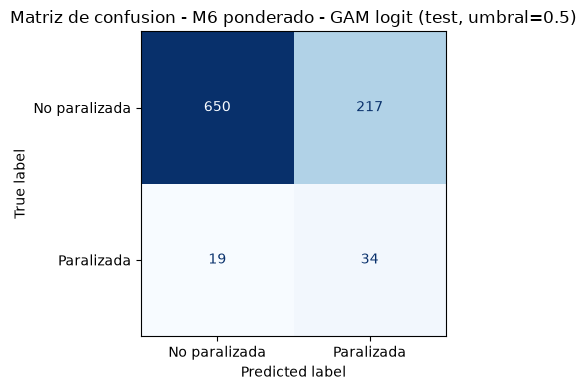

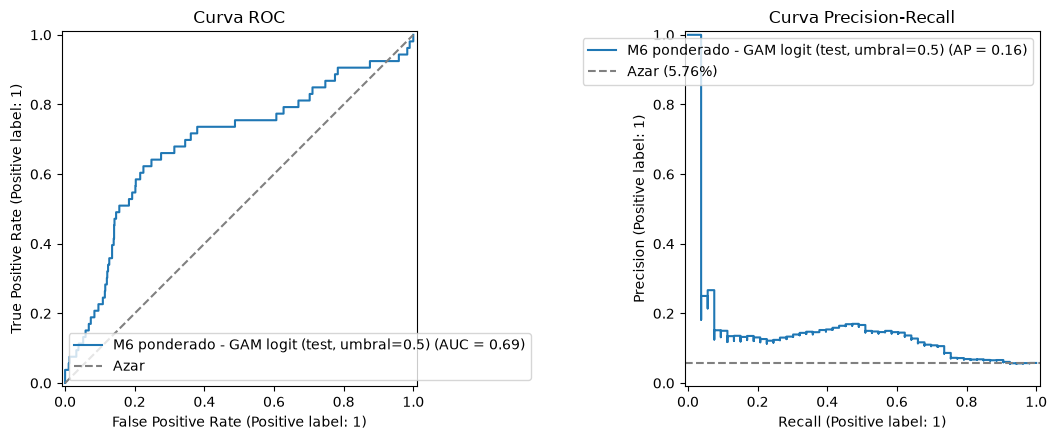

In [50]:
gam_m6_w = GLMGam(
    y_train_m2.to_numpy(),
    exog=X_linear_train_const,
    smoother=bs_gam,
    family=sm.families.Binomial(link=sm.families.links.Logit()),
    alpha=1.0,
)
result_m6_w = gam_m6_w.fit(weights=pesos_balanceados_train)

y_proba_m6_w = np.asarray(result_m6_w.predict(exog=X_linear_test_const, exog_smooth=X_smooth_test))
y_pred_m6_w = (y_proba_m6_w >= 0.5).astype(int)

metrics_m6_w = reporte_evaluacion(
    y_test_m2, y_pred_m6_w, y_proba_m6_w,
    nombre_modelo="M6 ponderado - GAM logit (test, umbral=0.5)"
)


In [51]:
importancia_m6_w = importancia_gam_statsmodels(
    result_m6_w, columnas_lineales, columnas_suaves, bs_gam, nombre_modelo="M6 ponderado - GAM logit"
)


**Variables y peso - M6 ponderado - GAM logit** (`peso` = coeficiente para variables lineales/dummy; suma de |coeficientes de la base de splines| para variables suaves)

| variable                                                           | tipo           |     peso |   p_valor |   abs_peso |
|:-------------------------------------------------------------------|:---------------|---------:|----------:|-----------:|
| numeric_standard__n_obras_relacionadas_proyecto                    | suave (spline) |  70.369  |  nan      |    70.369  |
| const                                                              | lineal         | -35.1093 |    0.9995 |    35.1093 |
| categorical__tipo_obra_nivel_1_Orden Público/Defensa Y Seguridad   | lineal         | -21.6566 |    0.9995 |    21.6566 |
| categorical__tipo_obra_nivel_1_infrequent_sklearn                  | lineal         | -19.454  |    0.9996 |    19.454  |
| numeric_standard__igeip_sector_ejecucion                           | suave (spline) |  13.8647 |  nan      |    13.8647 |
| target_encoded__provincia_target_enc                               | suave (spline) |  11.6635 |  nan      |    11.6635 |
| numeric_standard__inco_2024_entidad                                | suave (spline) |   7.8939 |  nan      |     7.8939 |
| woe__codigo_entidad_woe                                            | suave (spline) |   6.9837 |  nan      |     6.9837 |
| amount_log__monto_aprobado_soles_winsor_log                        | suave (spline) |   5.7496 |  nan      |     5.7496 |
| numeric_standard__igeip_sector                                     | suave (spline) |   5.396  |  nan      |     5.396  |
| woe__sector_entidad_woe                                            | suave (spline) |   3.7314 |  nan      |     3.7314 |
| target_encoded__tipo_obra_nivel_3_target_enc                       | suave (spline) |   2.8176 |  nan      |     2.8176 |
| categorical__naturaleza_obra_Instalación                           | lineal         |  -2.6602 |    0      |     2.6602 |
| target_encoded__departamento_target_enc                            | suave (spline) |   2.3551 |  nan      |     2.3551 |
| categorical__tipo_obra_nivel_1_Otras Infraestructuras              | lineal         |   1.6404 |    1      |     1.6404 |
| categorical__tipo_obra_nivel_1_Salud                               | lineal         |   1.5868 |    1      |     1.5868 |
| categorical__tipo_obra_nivel_1_Energía Y Minas                     | lineal         |   1.1856 |    1      |     1.1856 |
| categorical__tipo_obra_nivel_1_Vivienda Construcción Y Saneamiento | lineal         |   1.1097 |    1      |     1.1097 |
| categorical__naturaleza_obra_Reparación                            | lineal         |  -0.9491 |    0.1371 |     0.9491 |
| target_encoded__tipo_obra_nivel_2_target_enc                       | suave (spline) |   0.8865 |  nan      |     0.8865 |
| categorical__tipo_obra_nivel_1_Educación/Cultura                   | lineal         |   0.7511 |    1      |     0.7511 |
| categorical__tipo_obra_nivel_1_Agricultura                         | lineal         |  -0.6838 |    1      |     0.6838 |
| categorical__tipo_formato_5.0                                      | lineal         |   0.6177 |    0.1048 |     0.6177 |
| categorical__naturaleza_obra_Construcción/Creación                 | lineal         |  -0.6103 |    0.0854 |     0.6103 |
| categorical__naturaleza_obra_infrequent_sklearn                    | lineal         |  -0.5985 |    0.3377 |     0.5985 |
| categorical__naturaleza_obra_Rehabilitación                        | lineal         |   0.5634 |    0.2074 |     0.5634 |
| categorical__tipo_formato_2.0                                      | lineal         |   0.5571 |    0.0349 |     0.5571 |
| categorical__naturaleza_obra_Mejoramiento                          | lineal         |  -0.4835 |    0.1523 |     0.4835 |
| categorical__naturaleza_obra_Remodelación                          | lineal         |   0.4723 |    0.2824 |     0.4723 |
| categorical__tipo_obra_nivel_1_Transportes Y Comunicaciones        | lineal         |   0.4114 |    1      |     0.4114 |
| categorical__naturaleza_obra_Renovación                            | lineal         |   0.2492 |    0.5763 |     0.2492 |
| categorical__naturaleza_obra_Reconstrucción                        | lineal         |  -0.0758 |    0.8723 |     0.0758 |

#### M7 ponderado: GAM c-loglog con pesos de clase balanceados

c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\statsmodels\genmod\families\links.py:1035: RuntimeWarning: overflow encountered in exp
  return 1 - np.exp(-np.exp(z))


**Metricas globales - M7 ponderado - GAM c-loglog (test, umbral=0.5)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.5    |
| pr_auc    |  0.0576 |
| gini      |  0      |
| precision |  0.0576 |
| recall    |  1      |
| f1        |  0.1089 |
| f2        |  0.2341 |

**Reporte de clasificacion - M7 ponderado - GAM c-loglog (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0     |    0     |      0     |   867     |
| 1            |       0.058 |    1     |      0.109 |    53     |
| accuracy     |       0.058 |    0.058 |      0.058 |     0.058 |
| macro avg    |       0.029 |    0.5   |      0.054 |   920     |
| weighted avg |       0.003 |    0.058 |      0.006 |   920     |

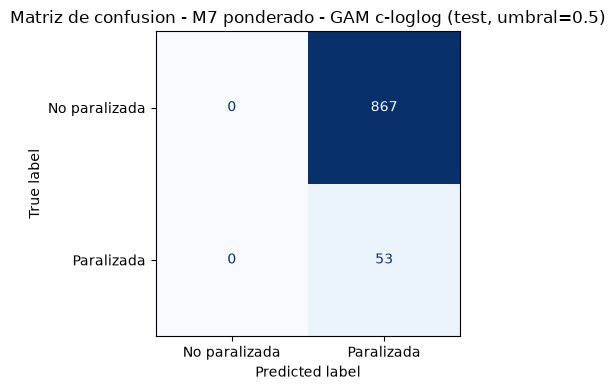

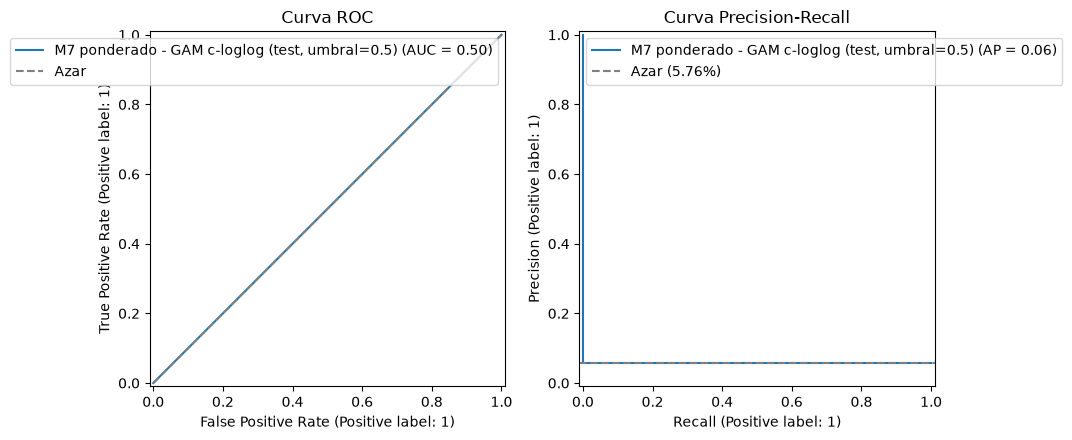

In [53]:
gam_m7_w = GLMGam(
    y_train_m2.to_numpy(),
    exog=X_linear_train_const,
    smoother=bs_gam,
    family=sm.families.Binomial(link=sm.families.links.CLogLog()),
    alpha=1.0,
)
result_m7_w = gam_m7_w.fit(weights=pesos_balanceados_train)

y_proba_m7_w = np.asarray(result_m7_w.predict(exog=X_linear_test_const, exog_smooth=X_smooth_test))
y_pred_m7_w = (y_proba_m7_w >= 0.5).astype(int)

metrics_m7_w = reporte_evaluacion(
    y_test_m2, y_pred_m7_w, y_proba_m7_w,
    nombre_modelo="M7 ponderado - GAM c-loglog (test, umbral=0.5)"
)


In [54]:
importancia_m7_w = importancia_gam_statsmodels(
    result_m7_w, columnas_lineales, columnas_suaves, bs_gam, nombre_modelo="M7 ponderado - GAM c-loglog"
)


**Variables y peso - M7 ponderado - GAM c-loglog** (`peso` = coeficiente para variables lineales/dummy; suma de |coeficientes de la base de splines| para variables suaves)

| variable                                                           | tipo           |         peso |   p_valor |    abs_peso |
|:-------------------------------------------------------------------|:---------------|-------------:|----------:|------------:|
| numeric_standard__n_obras_relacionadas_proyecto                    | suave (spline) |  4.26639e+13 |       nan | 4.26639e+13 |
| woe__codigo_entidad_woe                                            | suave (spline) |  9.71942e+12 |       nan | 9.71942e+12 |
| woe__sector_entidad_woe                                            | suave (spline) |  9.34865e+12 |       nan | 9.34865e+12 |
| numeric_standard__igeip_sector                                     | suave (spline) |  8.84548e+12 |       nan | 8.84548e+12 |
| amount_log__monto_aprobado_soles_winsor_log                        | suave (spline) |  8.7191e+12  |       nan | 8.7191e+12  |
| const                                                              | lineal         |  8.70115e+12 |         0 | 8.70115e+12 |
| numeric_standard__igeip_sector_ejecucion                           | suave (spline) |  7.40747e+12 |       nan | 7.40747e+12 |
| numeric_standard__inco_2024_entidad                                | suave (spline) |  6.78371e+12 |       nan | 6.78371e+12 |
| target_encoded__tipo_obra_nivel_3_target_enc                       | suave (spline) |  6.22545e+12 |       nan | 6.22545e+12 |
| target_encoded__tipo_obra_nivel_2_target_enc                       | suave (spline) |  6.01911e+12 |       nan | 6.01911e+12 |
| target_encoded__departamento_target_enc                            | suave (spline) |  5.58023e+12 |       nan | 5.58023e+12 |
| target_encoded__provincia_target_enc                               | suave (spline) |  5.34555e+12 |       nan | 5.34555e+12 |
| categorical__tipo_formato_5.0                                      | lineal         |  5.06796e+12 |         0 | 5.06796e+12 |
| categorical__naturaleza_obra_Rehabilitación                        | lineal         |  3.97978e+12 |         0 | 3.97978e+12 |
| categorical__tipo_obra_nivel_1_Transportes Y Comunicaciones        | lineal         |  2.32489e+12 |         0 | 2.32489e+12 |
| categorical__tipo_obra_nivel_1_Agricultura                         | lineal         |  1.90618e+12 |         0 | 1.90618e+12 |
| categorical__tipo_formato_2.0                                      | lineal         |  1.68772e+12 |         0 | 1.68772e+12 |
| categorical__tipo_obra_nivel_1_Energía Y Minas                     | lineal         |  1.64686e+12 |         0 | 1.64686e+12 |
| categorical__naturaleza_obra_Mejoramiento                          | lineal         |  1.51194e+12 |         0 | 1.51194e+12 |
| categorical__tipo_obra_nivel_1_Educación/Cultura                   | lineal         |  1.47208e+12 |         0 | 1.47208e+12 |
| categorical__naturaleza_obra_Reconstrucción                        | lineal         |  9.76688e+11 |         0 | 9.76688e+11 |
| categorical__naturaleza_obra_Construcción/Creación                 | lineal         |  6.99047e+11 |         0 | 6.99047e+11 |
| categorical__tipo_obra_nivel_1_Vivienda Construcción Y Saneamiento | lineal         |  5.79735e+11 |         0 | 5.79735e+11 |
| categorical__tipo_obra_nivel_1_Salud                               | lineal         |  4.29839e+11 |         0 | 4.29839e+11 |
| categorical__naturaleza_obra_Renovación                            | lineal         |  4.20802e+11 |         0 | 4.20802e+11 |
| categorical__tipo_obra_nivel_1_Otras Infraestructuras              | lineal         |  3.49394e+11 |         0 | 3.49394e+11 |
| categorical__naturaleza_obra_Remodelación                          | lineal         |  2.91368e+11 |         0 | 2.91368e+11 |
| categorical__naturaleza_obra_infrequent_sklearn                    | lineal         |  1.1892e+11  |         0 | 1.1892e+11  |
| categorical__naturaleza_obra_Reparación                            | lineal         |  1.16566e+11 |         0 | 1.16566e+11 |
| categorical__naturaleza_obra_Instalación                           | lineal         |  3.79461e+10 |         0 | 3.79461e+10 |
| categorical__tipo_obra_nivel_1_Orden Público/Defensa Y Seguridad   | lineal         | -6.9022e+09  |         0 | 6.9022e+09  |
| categorical__tipo_obra_nivel_1_infrequent_sklearn                  | lineal         | -9.16719e+08 |         0 | 9.16719e+08 |

## 10. Comparativa final ampliada (todas las variantes, test, umbral=0.5)

In [55]:
comparativa_final = pd.DataFrame(
    [
        metrics_m2, metrics_m4, metrics_m4_w, metrics_m5, metrics_m5_w,
        metrics_m6, metrics_m6_w, metrics_m7, metrics_m7_w, metrics_rf,
    ],
    index=[
        "M2 - Regresion logistica",
        "M4 - GLM c-loglog",
        "M4 ponderado - GLM c-loglog",
        "M5 - GLM probit",
        "M5 ponderado - GLM probit",
        "M6 - GAM logit",
        "M6 ponderado - GAM logit",
        "M7 - GAM c-loglog",
        "M7 ponderado - GAM c-loglog",
        "RF - Random Forest",
    ],
)
display(Markdown(comparativa_final.round(4).to_markdown()))


|                             |   roc_auc |   pr_auc |   gini |   precision |   recall |     f1 |     f2 |
|:----------------------------|----------:|---------:|-------:|------------:|---------:|-------:|-------:|
| M2 - Regresion logistica    |    0.7074 |   0.1335 | 0.4147 |      0.0981 |   0.6792 | 0.1714 | 0.3109 |
| M4 - GLM c-loglog           |    0.5336 |   0.0634 | 0.0672 |      0.0918 |   0.1698 | 0.1192 | 0.1452 |
| M4 ponderado - GLM c-loglog |    0.5261 |   0.0616 | 0.0522 |      0.0811 |   0.1698 | 0.1098 | 0.1393 |
| M5 - GLM probit             |    0.5047 |   0.0582 | 0.0093 |      0.0682 |   0.0566 | 0.0619 | 0.0586 |
| M5 ponderado - GLM probit   |    0.5238 |   0.0608 | 0.0476 |      0.0719 |   0.2264 | 0.1091 | 0.1583 |
| M6 - GAM logit              |    0.708  |   0.1866 | 0.416  |      0.2273 |   0.0943 | 0.1333 | 0.1068 |
| M6 ponderado - GAM logit    |    0.6877 |   0.1574 | 0.3754 |      0.1355 |   0.6415 | 0.2237 | 0.3672 |
| M7 - GAM c-loglog           |    0.7109 |   0.1955 | 0.4218 |      0.2083 |   0.0943 | 0.1299 | 0.1059 |
| M7 ponderado - GAM c-loglog |    0.5    |   0.0576 | 0      |      0.0576 |   1      | 0.1089 | 0.2341 |
| RF - Random Forest          |    0.6477 |   0.1533 | 0.2955 |      0.1261 |   0.283  | 0.1744 | 0.2266 |